# Pathological Search Suite: Sequential Locks, Signalling Activation & Pairwise Interaction Screens

This notebook loads, verifies, and renders all three benchmark families extending Confounder-Eliminating Actor-Critic (CEAC) beyond two-step junctions:

1. **Sequential Combination Lock & Bidirectional ("Diabolical") Combination Lock (`ceac_pathologies`, `locks`)** — Sweeps gated lock horizon $L \in \{1, 2, 3, 4\}$ ($H = L + 1$) with anti-shaped step costs, a 3-lane diffusing dead-end sink, and an opposing $0.50$ decoy chain while holding route returns and diagnostic KL strictly invariant across depth.
2. **Epistatic Signalling / Protein Activation under Pleiotropic Confounding (`ceac_pathologies`, `epistasis`)** — Tests discovery of a $1$-in-$128$ rare synthetic-rescue responder amidst $k \in \{0, 1, 2, 3\}$ non-causal passenger-omics channels ($M = 128 \cdot 2^k \in \{128, 256, 512, 1024\}$) and $4^k - 1 \in \{0, 3, 15, 63\}$ zero-reward off-pathway pleiotropic states.
3. **Pairwise Interaction Screen on the Published Horlbeck 2018 K562 Matrix + Greedy Price-Ranked CEAC (`ceac_gi` & `ceac_ranked`)** — Evaluates sequential pairwise discovery on a verified 10-variable / 45-pair human K562 interaction score panel (`FDPS–PPP2R1A`, $\text{GI} = -5.24$) under $k \in \{0, 1, 2, 3\}$ non-causal single-variable main-effect confounders, comparing certified Section-3 `ceac` against the **greedy maximally-disagreeing + dynamic evidence-price ranked replay** extension (`ceac_ranked`) and Russo–Van Roy optimal-action-MI IDS (`ids_action`).

All figures are rendered live from compact, SHA-256-verified portable exports under `notebooks/evidence/`; raw `/runs` trajectories are never required and no training is launched when executing the notebook.


In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "ceac_pathologies").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from IPython import get_ipython
_ip = get_ipython()
if _ip is not None:
    _ip.run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import numpy as np

from ceac_pathologies.report import (
    KINDS,
    LABELS,
    draw_architecture,
    draw_epistasis_discovery_traces,
    draw_learning,
    draw_mechanisms,
    draw_response,
    endpoints,
    load_export,
    paired_ceac_comparisons,
)
from ceac_ranked.study import (
    RANKED_LABELS,
    draw_gi_discovery_traces,
    draw_gi_ranked_learning,
    draw_gi_ranked_mechanisms,
    draw_gi_ranked_response,
    load_gi_ranked_export,
)

locks = load_export(ROOT / "notebooks/evidence/pathologies_locks")
epistasis = load_export(ROOT / "notebooks/evidence/pathologies_epistasis")
gi_ranked = load_gi_ranked_export(ROOT / "notebooks/evidence/pathologies_gi_ranked")

print(
    f"Verified portable exports: {len(locks['runs'])} lock cells, "
    f"{len(epistasis['runs'])} signalling-activation cells, and "
    f"{len(gi_ranked['sweep_rows'])} GI sweep + {len(gi_ranked['calibration_rows'])} GI calibration cells. "
    "No training launched."
)


Verified portable exports: 192 lock cells, 108 signalling-activation cells, and 288 GI sweep + 48 GI calibration cells. No training launched.


## 1. Sequential Combination Lock & Bidirectional ("Diabolical") Lock (`locks`)

Both lock families share the calibrated $L = 1$ easy baseline (`seeds 1001, 1002`, `tasks 0, 1`, `late_gap <= 0.025`). Increasing $L \in \{1, 2, 3, 4\}$ adds gated key steps with step tension $-0.004$ (rebated at the terminal gate so route returns remain identically $0.50$, $0.10/0.90$, and $0.48$) while wrong keys drop irreversibly into a 3-lane zero-cost dead sink. In `bidirectional_lock`, an opposing left chain unlocks deterministic $0.50$ under key $0$ while the right target chain requires key $1$.


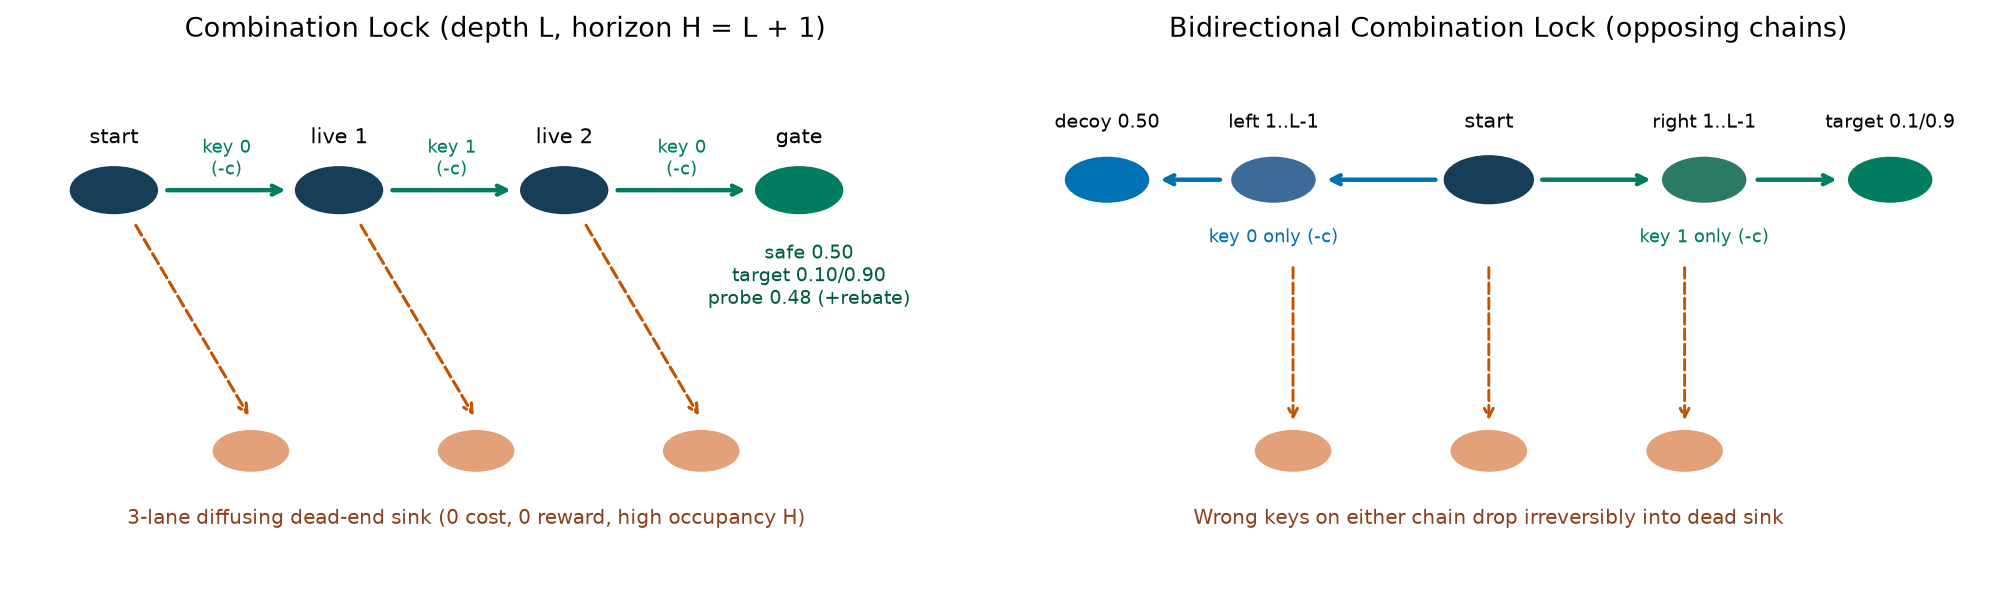

In [2]:
fig = draw_architecture("locks")
plt.show()


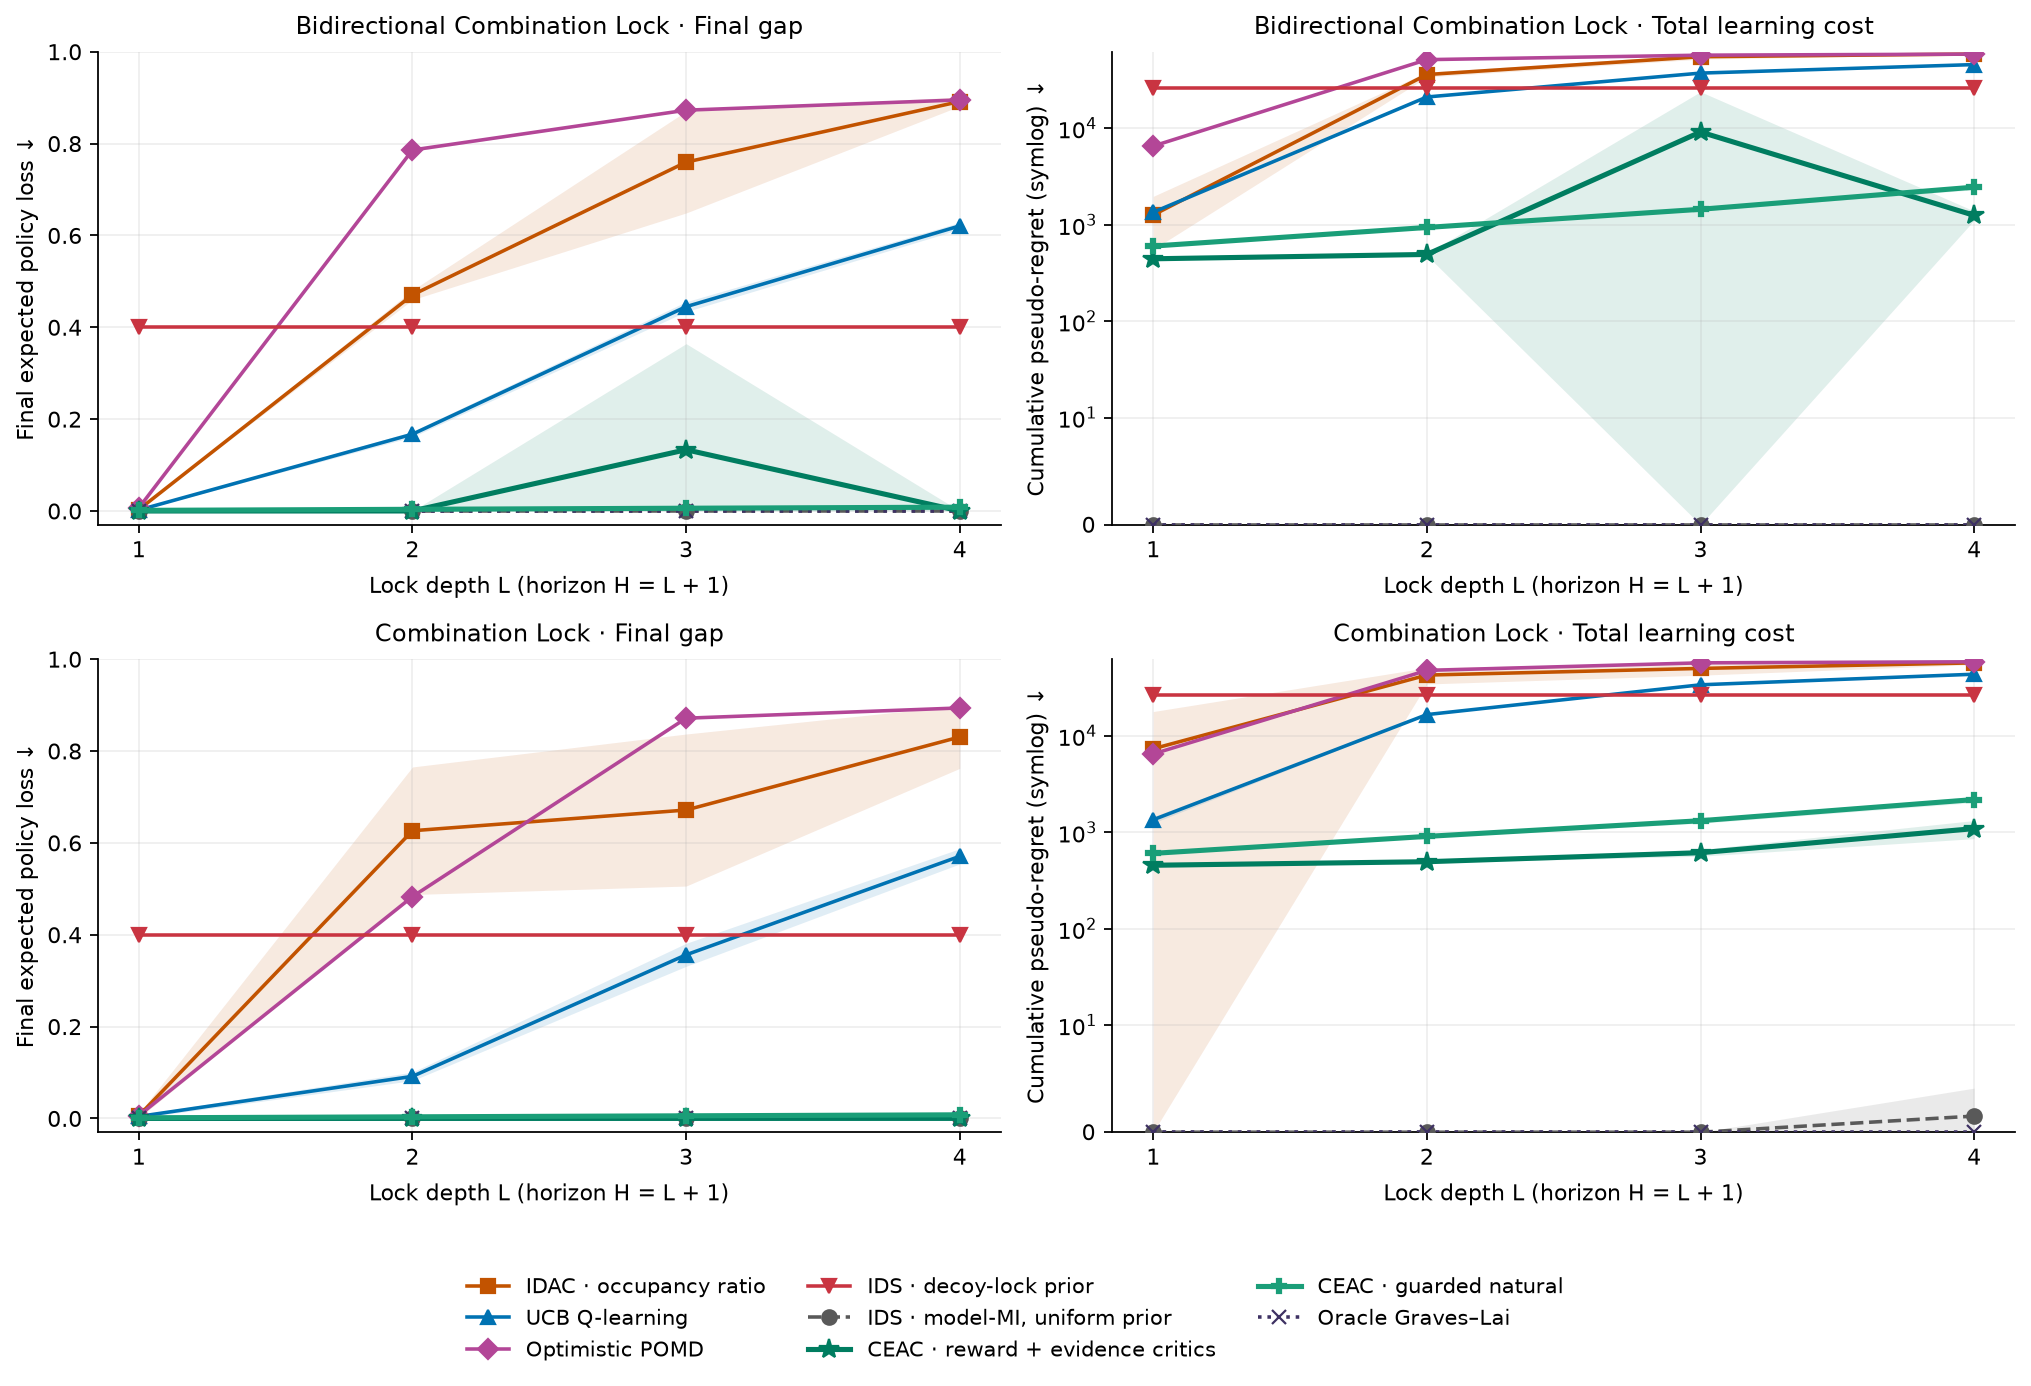

In [3]:
fig = draw_response(locks)
plt.show()


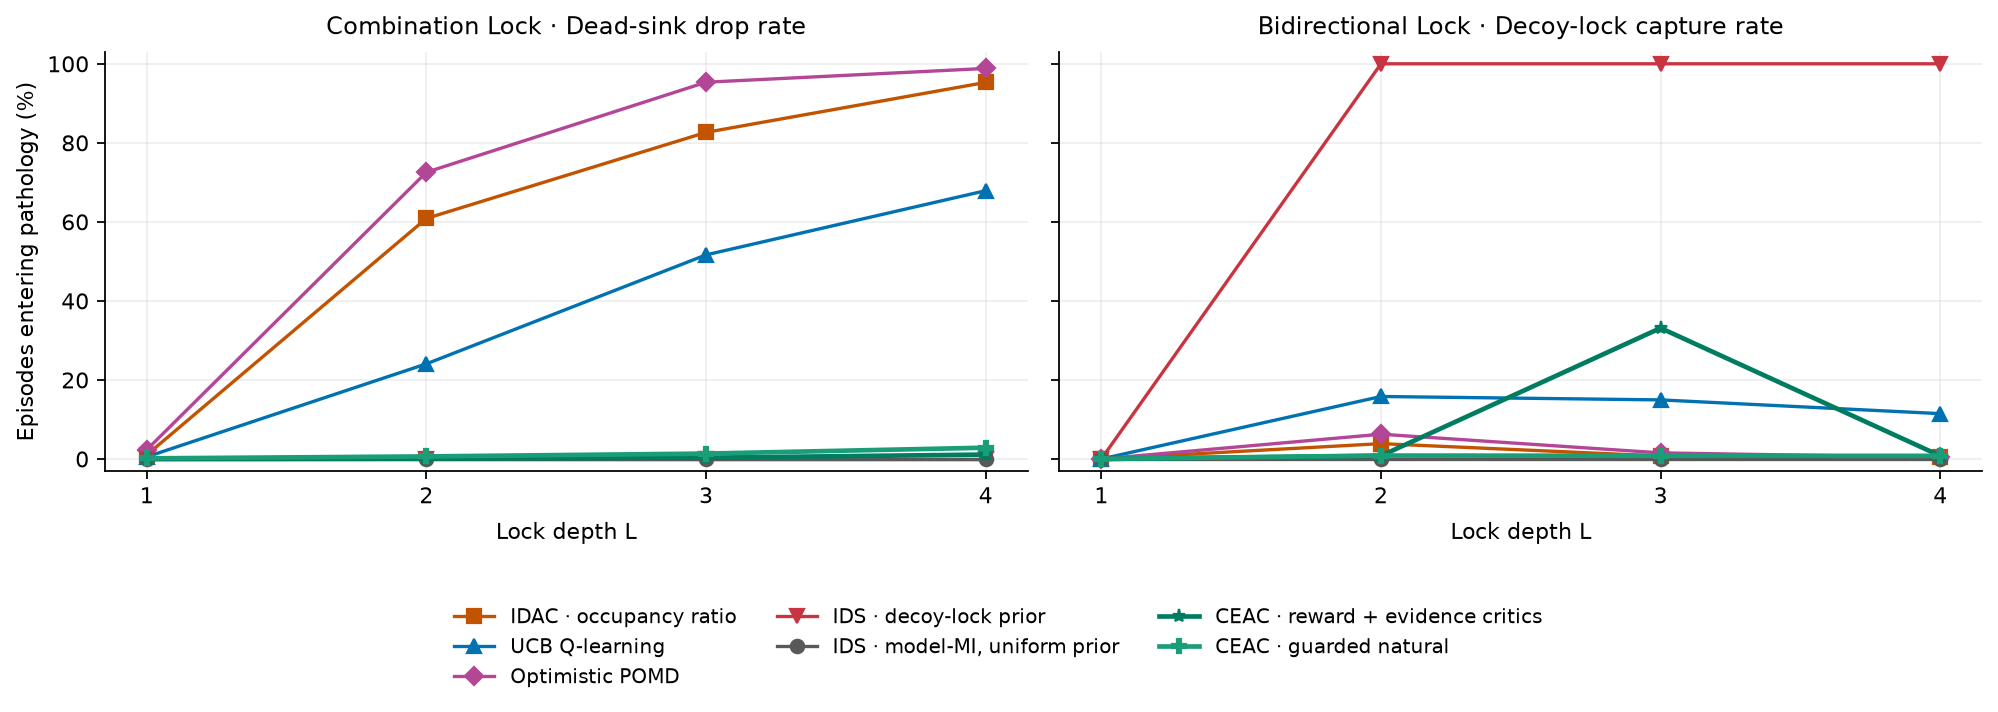

In [4]:
fig = draw_mechanisms(locks)
plt.show()


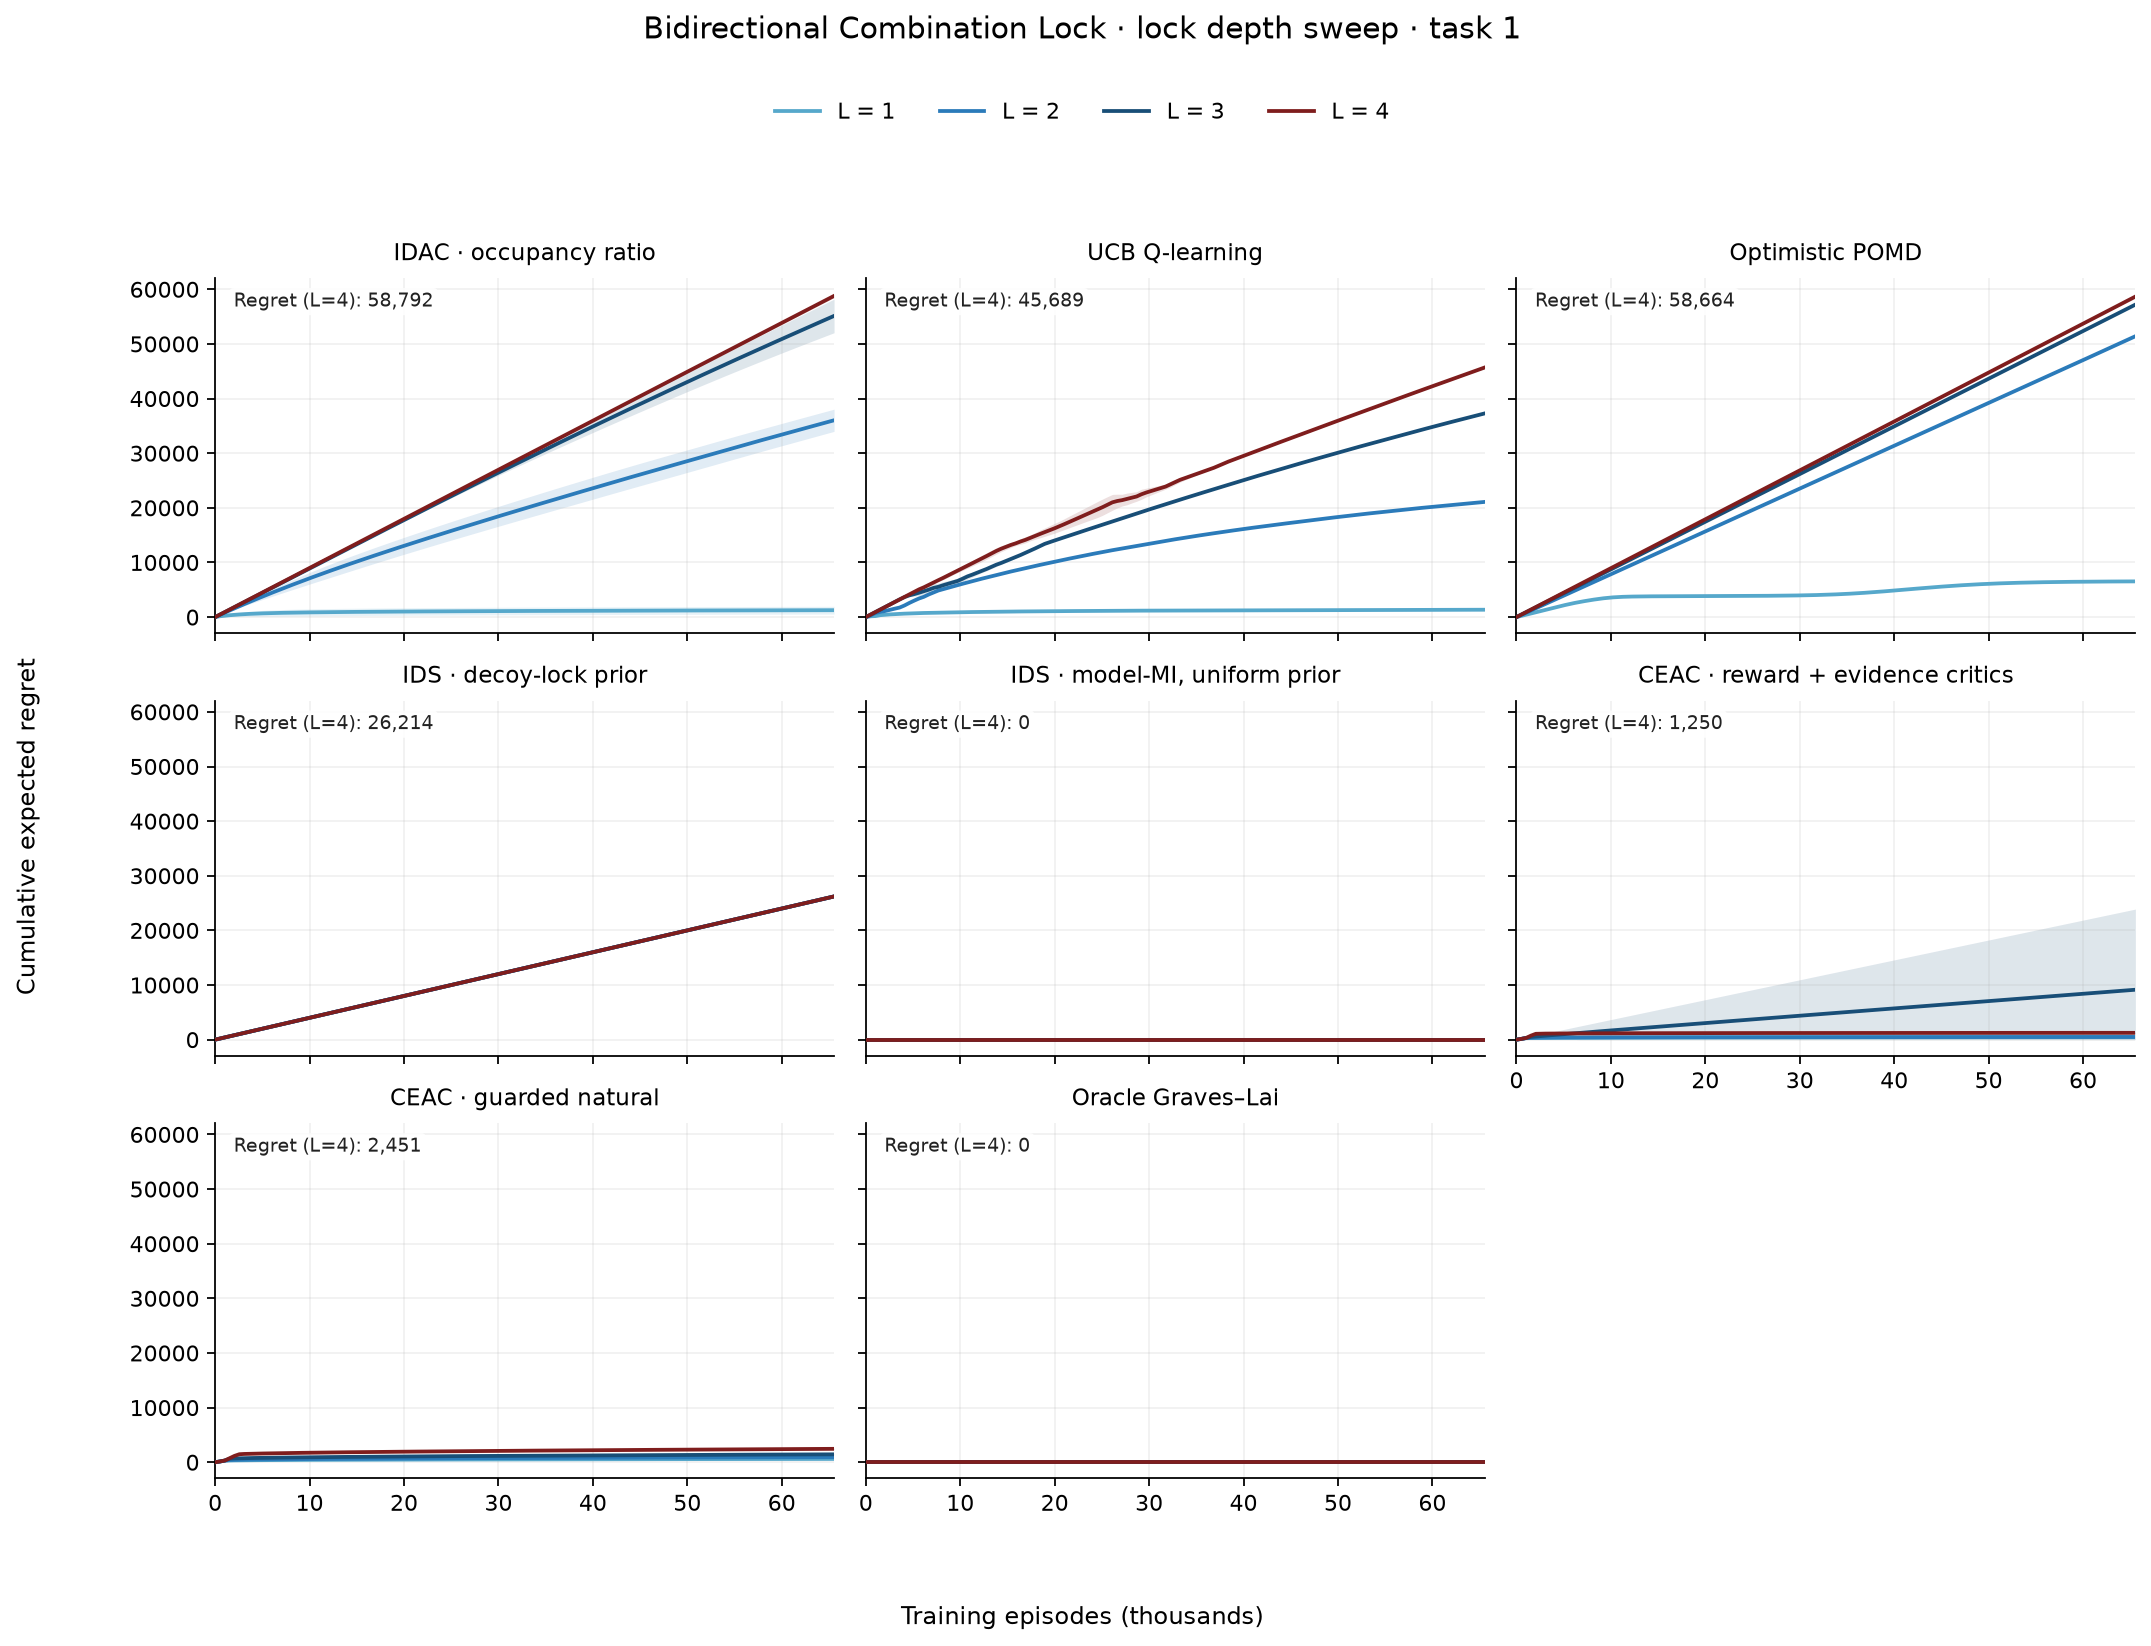

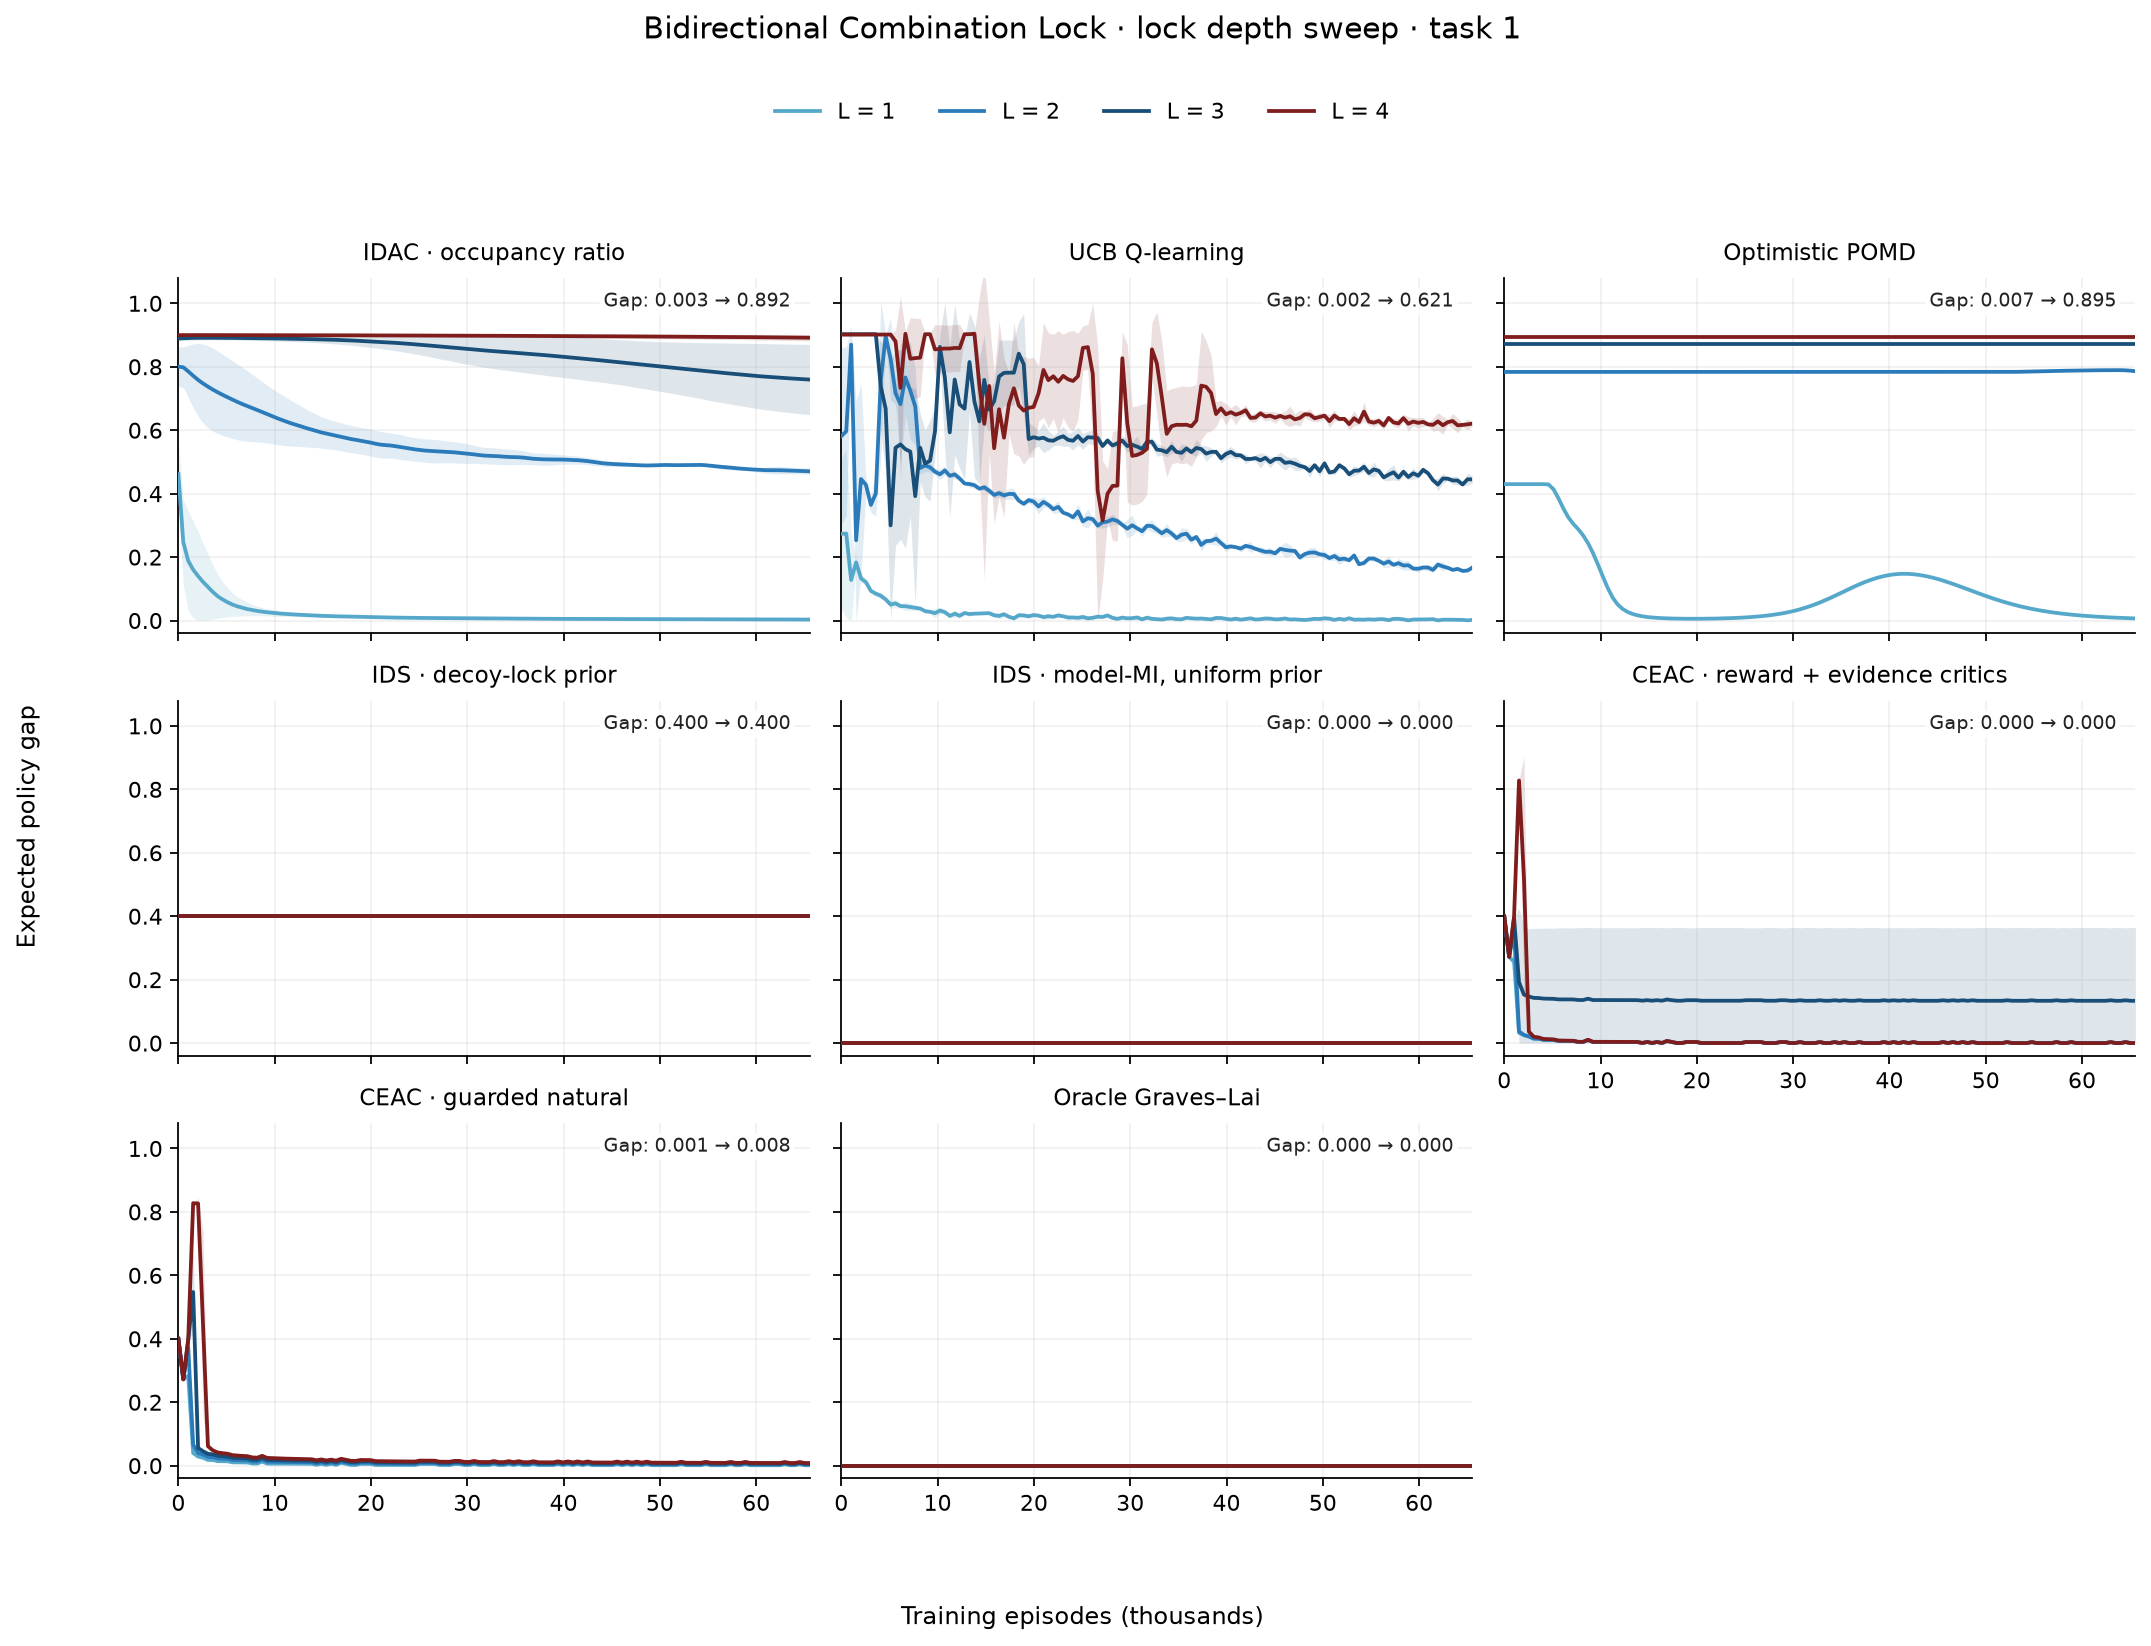

In [5]:
for metric in ("cumulative_regret", "window_gap"):
    fig = draw_learning(locks, "bidirectional_lock", task=1, metric=metric)
    plt.show()


In [6]:
lock_rows = [r for r in endpoints(locks) if r["task"] == 1 and r["dose"] in (1, 4)]
print(f"{'Environment':32s} | {'Algorithm':34s} | {'L=1 Regret':>11s} | {'L=4 Regret':>11s} | {'L=4 Gap':>8s}")
print("-" * 108)
for kind in ("bidirectional_lock", "combination_lock"):
    by_m = { (r["method"], r["dose"]): r for r in lock_rows if r["kind"] == kind }
    for m in ("idac", "pomd", "ucb_q", "ids_decoy", "ids_product", "ceac", "ceac_natural", "oracle"):
        r1, r4 = by_m[(m, 1)], by_m[(m, 4)]
        print(f"{KINDS[kind]:32s} | {LABELS[m]:34s} | {r1['regret_mean']:11,.1f} | {r4['regret_mean']:11,.1f} | {r4['late_gap_mean']:8.4f}")


Environment                      | Algorithm                          |  L=1 Regret |  L=4 Regret |  L=4 Gap
------------------------------------------------------------------------------------------------------------
Bidirectional Combination Lock   | IDAC · occupancy ratio             |     1,260.4 |    58,791.9 |   0.8916
Bidirectional Combination Lock   | Optimistic POMD                    |     6,533.7 |    58,663.9 |   0.8951
Bidirectional Combination Lock   | UCB Q-learning                     |     1,346.7 |    45,688.7 |   0.6208
Bidirectional Combination Lock   | IDS · decoy-lock prior             |    26,214.4 |    26,214.4 |   0.4000
Bidirectional Combination Lock   | IDS · model-MI, uniform prior      |         0.0 |         0.0 |   0.0000
Bidirectional Combination Lock   | CEAC · reward + evidence critics   |       443.1 |     1,249.8 |   0.0001
Bidirectional Combination Lock   | CEAC · guarded natural             |       600.2 |     2,450.9 |   0.0083
Bidirectional Combi

## 2. Signalling Pathway / Protein Activation under Off-Pathway Pleiotropy (`epistasis`)

Models discovering a rare $1$-in-$128$ synthetic-rescue signalling subtype (`K1 ∧ K2` synergy pays $0.90$ vs. $0.10$ in $127$ non-responders; baseline care pays $0.50$; phospho-probe pays $0.48$) as $k \in \{0, 1, 2, 3\}$ non-causal passenger modules ($\eta \in \{0, 1\}^k$, $M = 128 \cdot 2^k$) and $4^k - 1$ zero-reward off-pathway pleiotropic arms are added.

- **Whole-model MI (`ids_product`) vs. Optimal-action MI (`ids_action`)**: Whole-model mutual information $I((\theta, \eta); Z^\pi)$ spends early episodes profiling decision-irrelevant passenger-omics channels, whereas Russo–Van Roy optimal-action MI $I(A^\star; Z^\pi)$ and CEAC's coordinate-free row dominance assign **zero** value to passenger channels.
- **Model-free coverage / bonus collapse**: `IDAC`, `Optimistic POMD`, and `UCB-Q` are drawn into the $4^k - 1$ off-pathway states as $k$ increases.


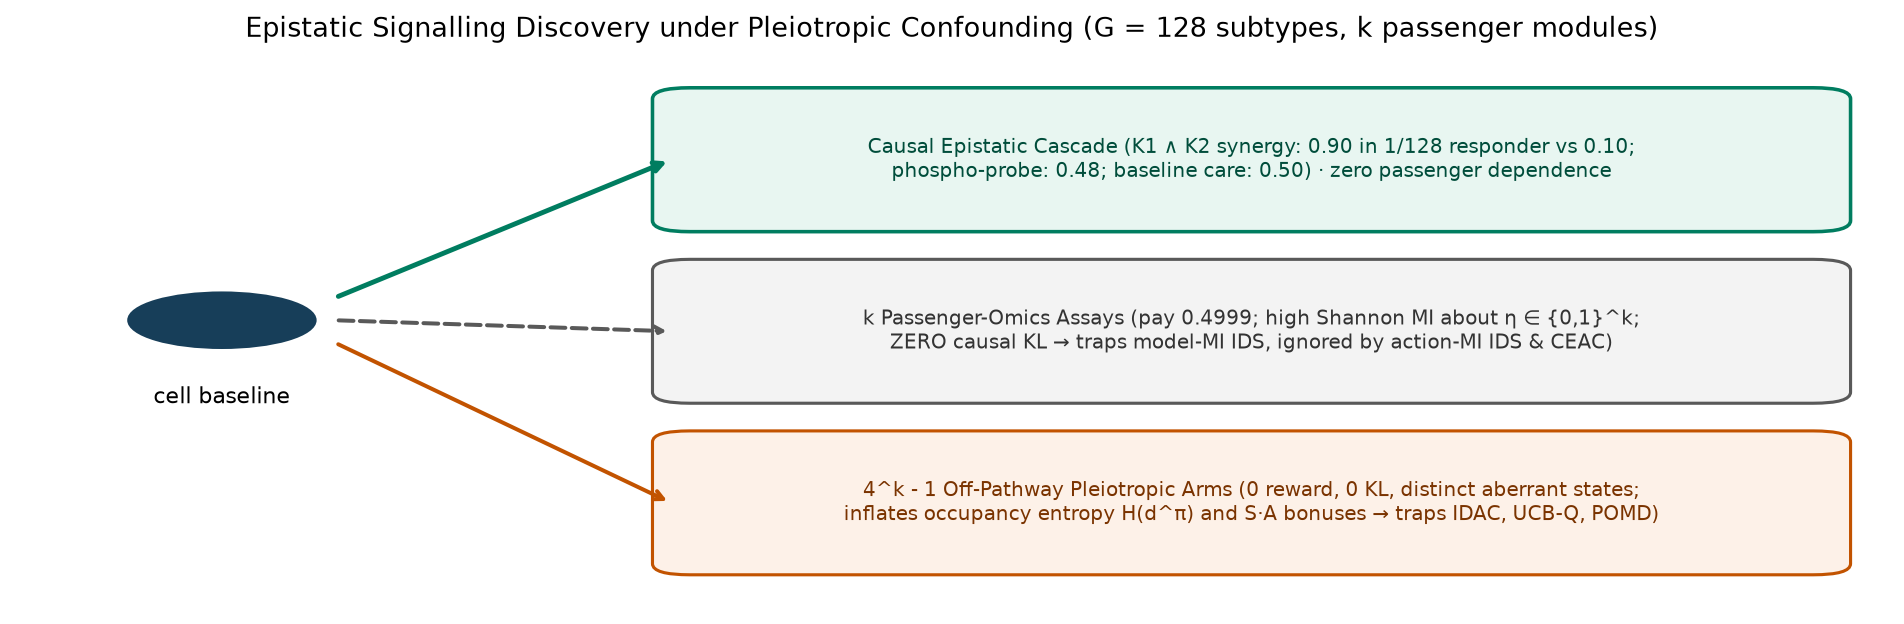

In [7]:
fig = draw_architecture("epistasis")
plt.show()


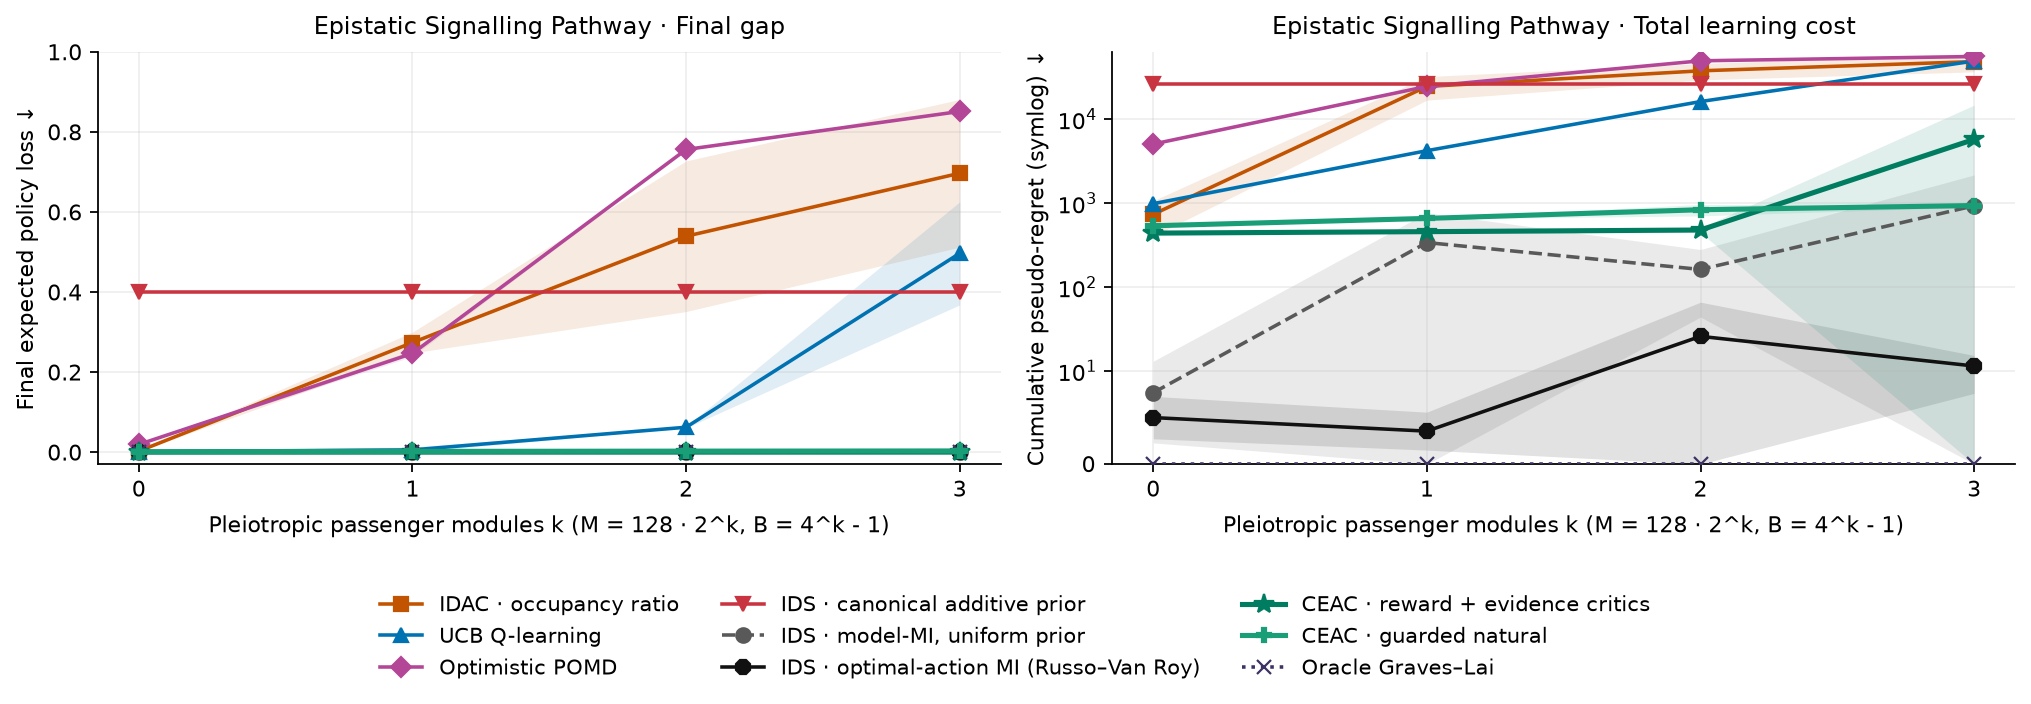

In [8]:
fig = draw_response(epistasis)
plt.show()


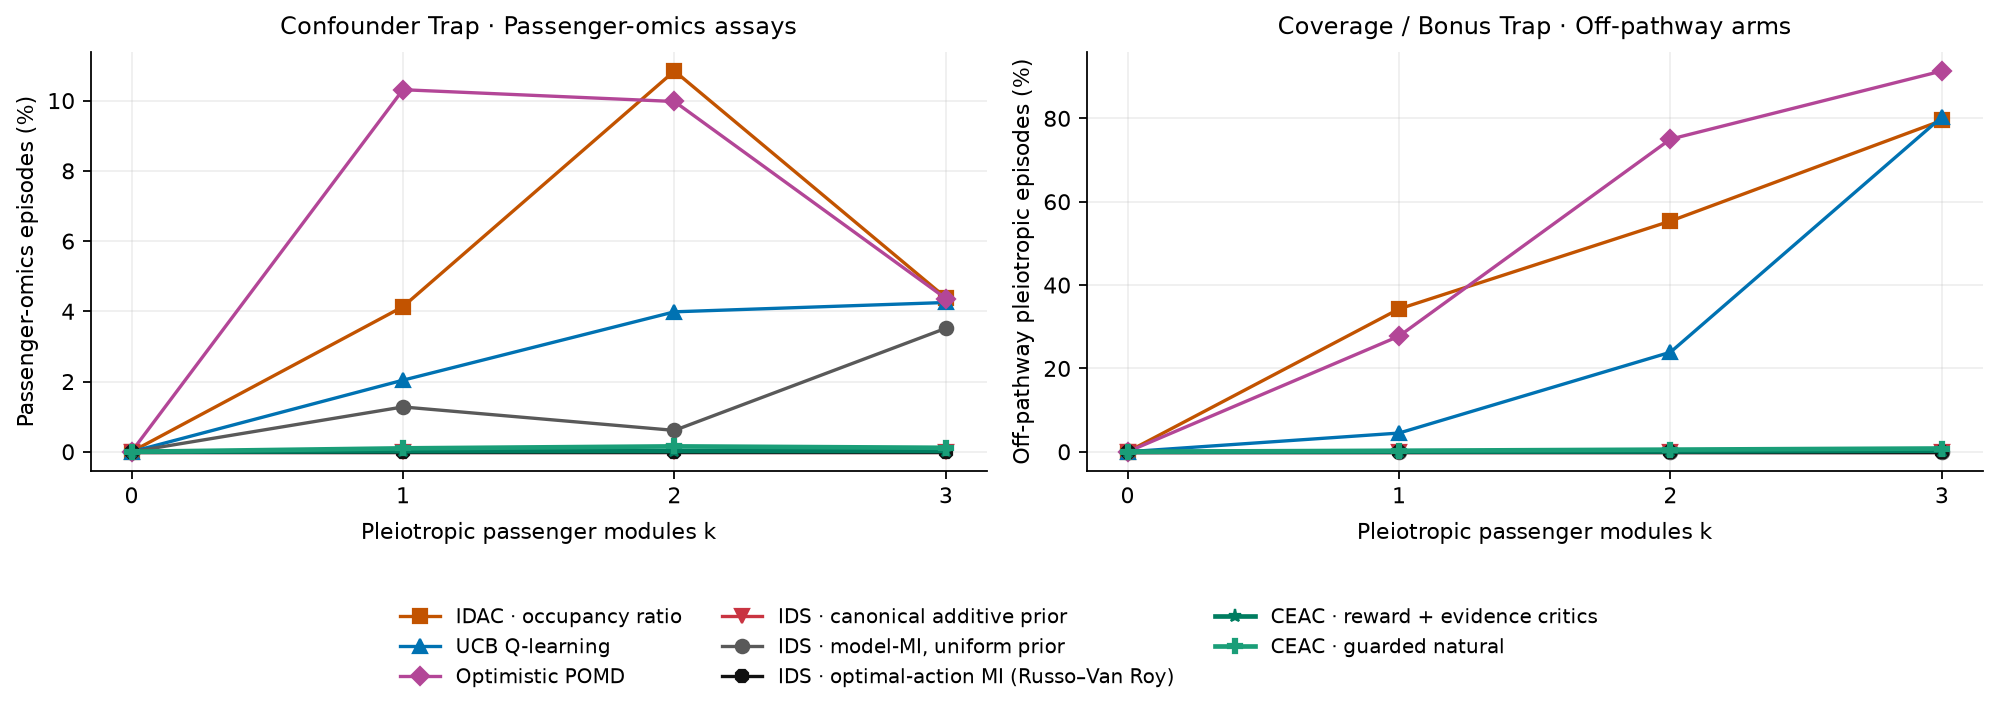

In [9]:
fig = draw_mechanisms(epistasis)
plt.show()


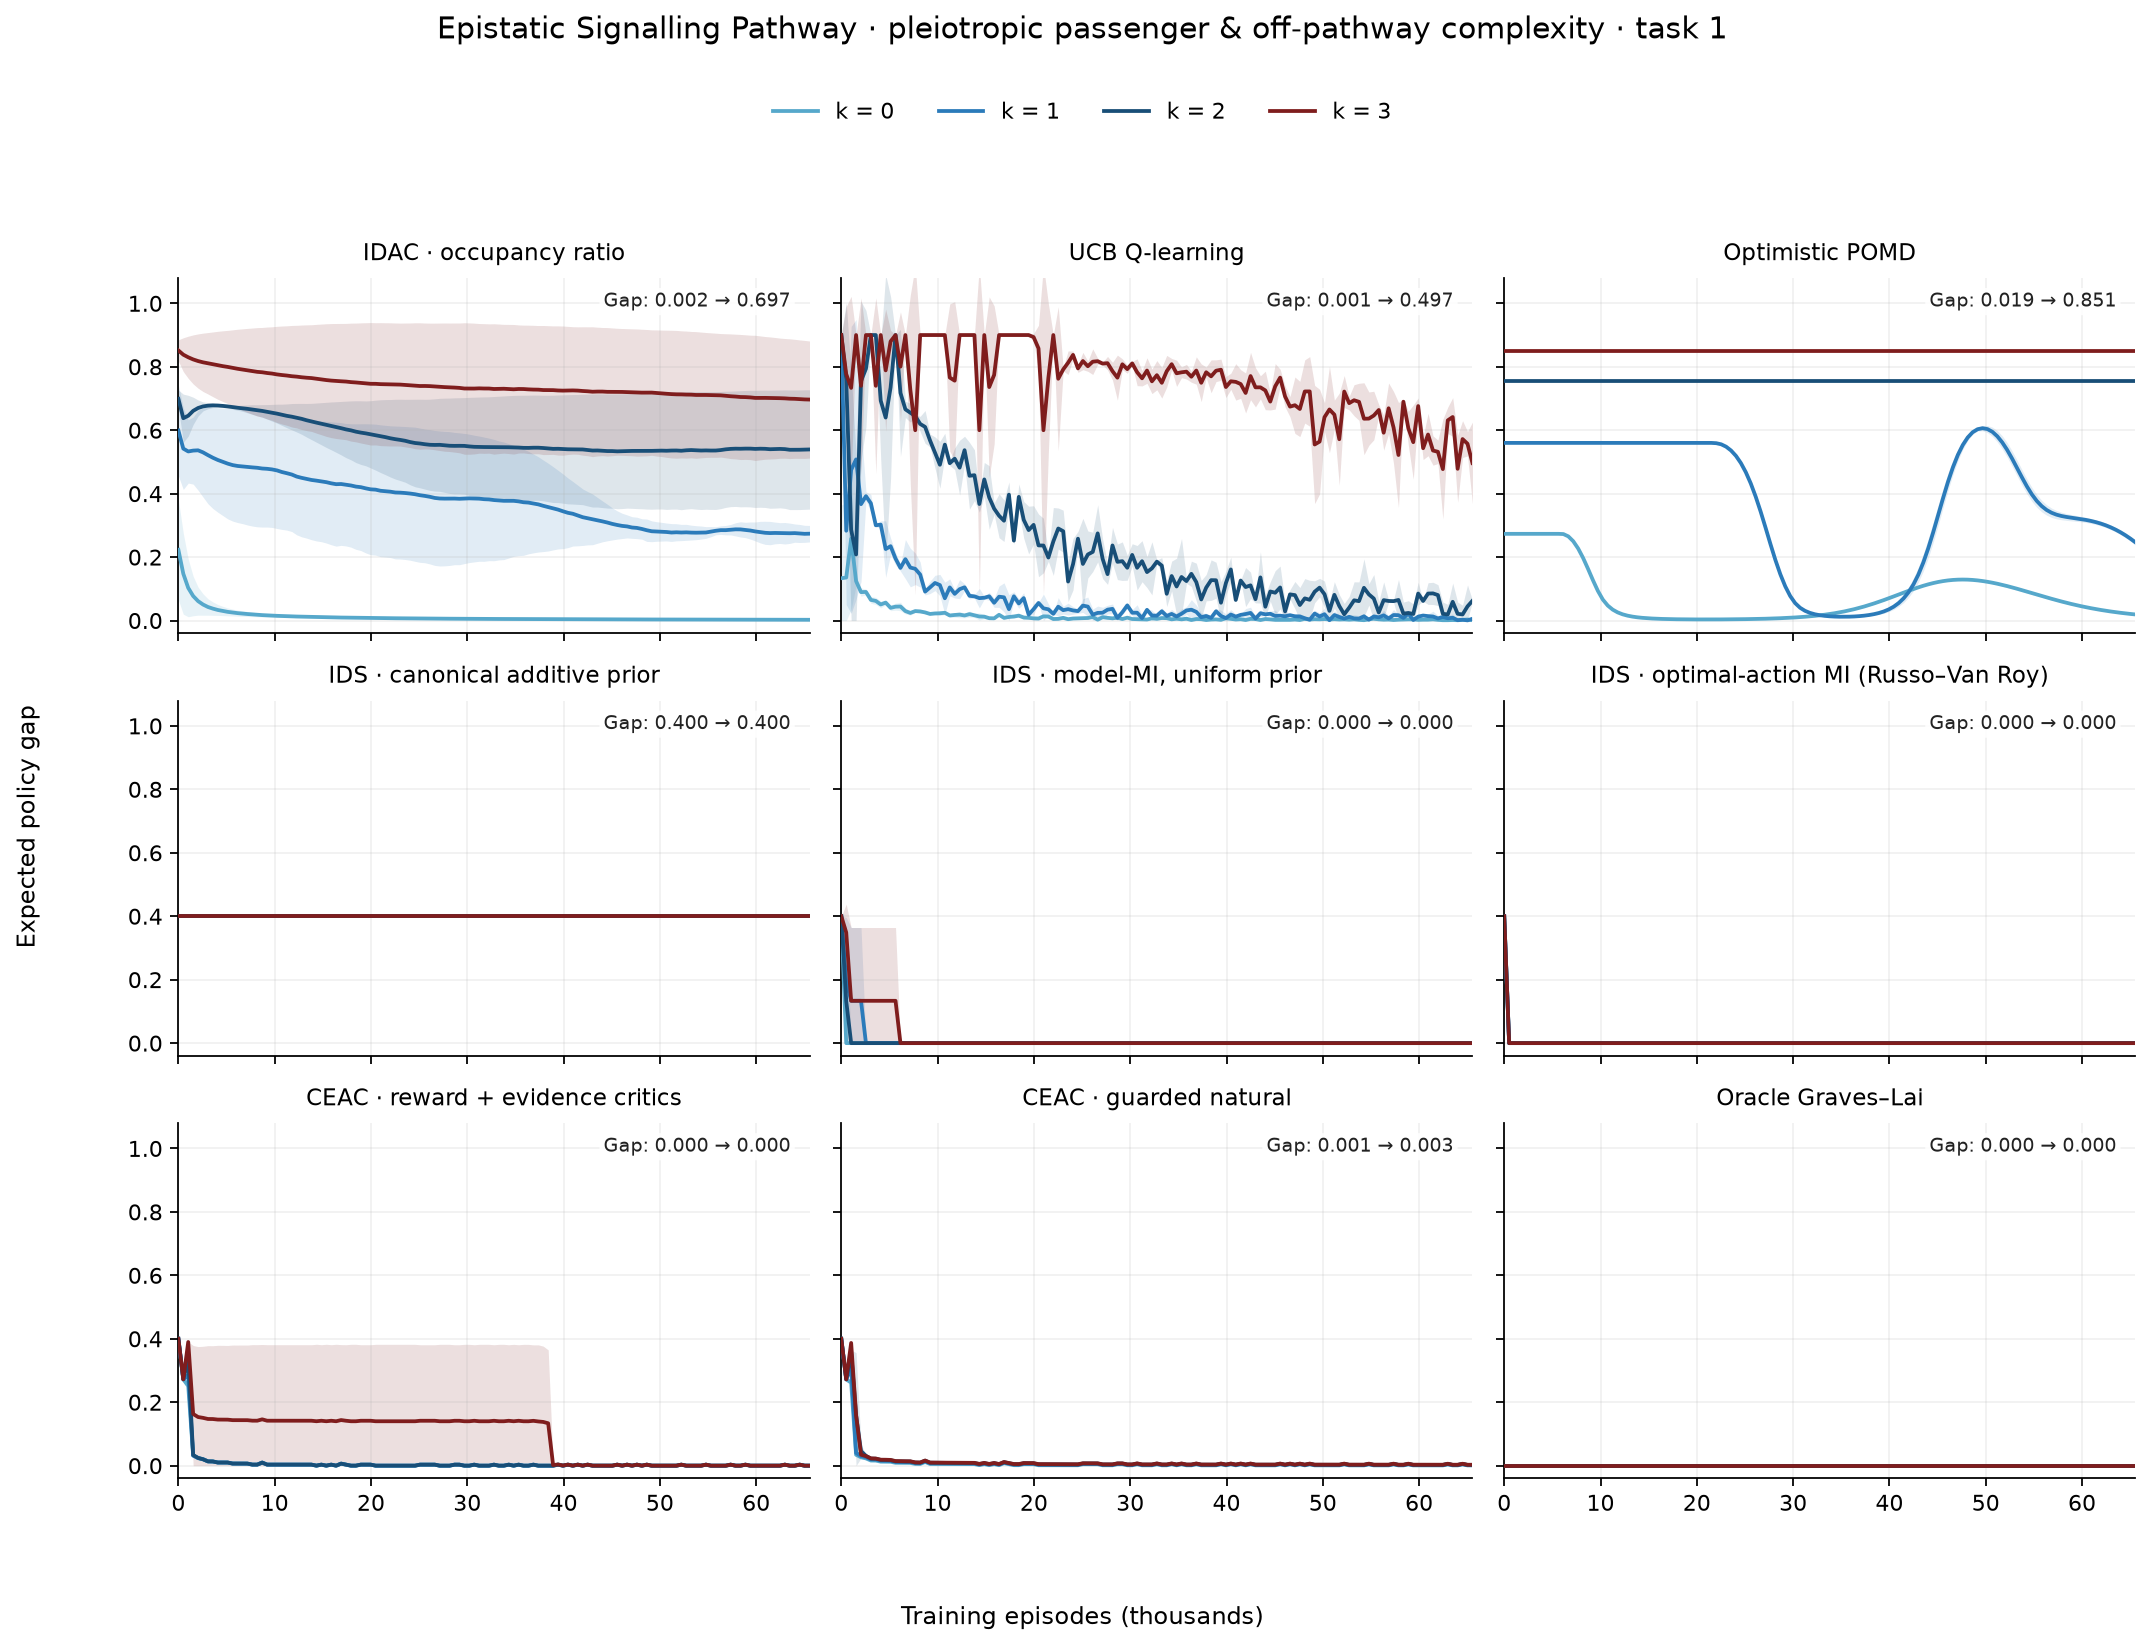

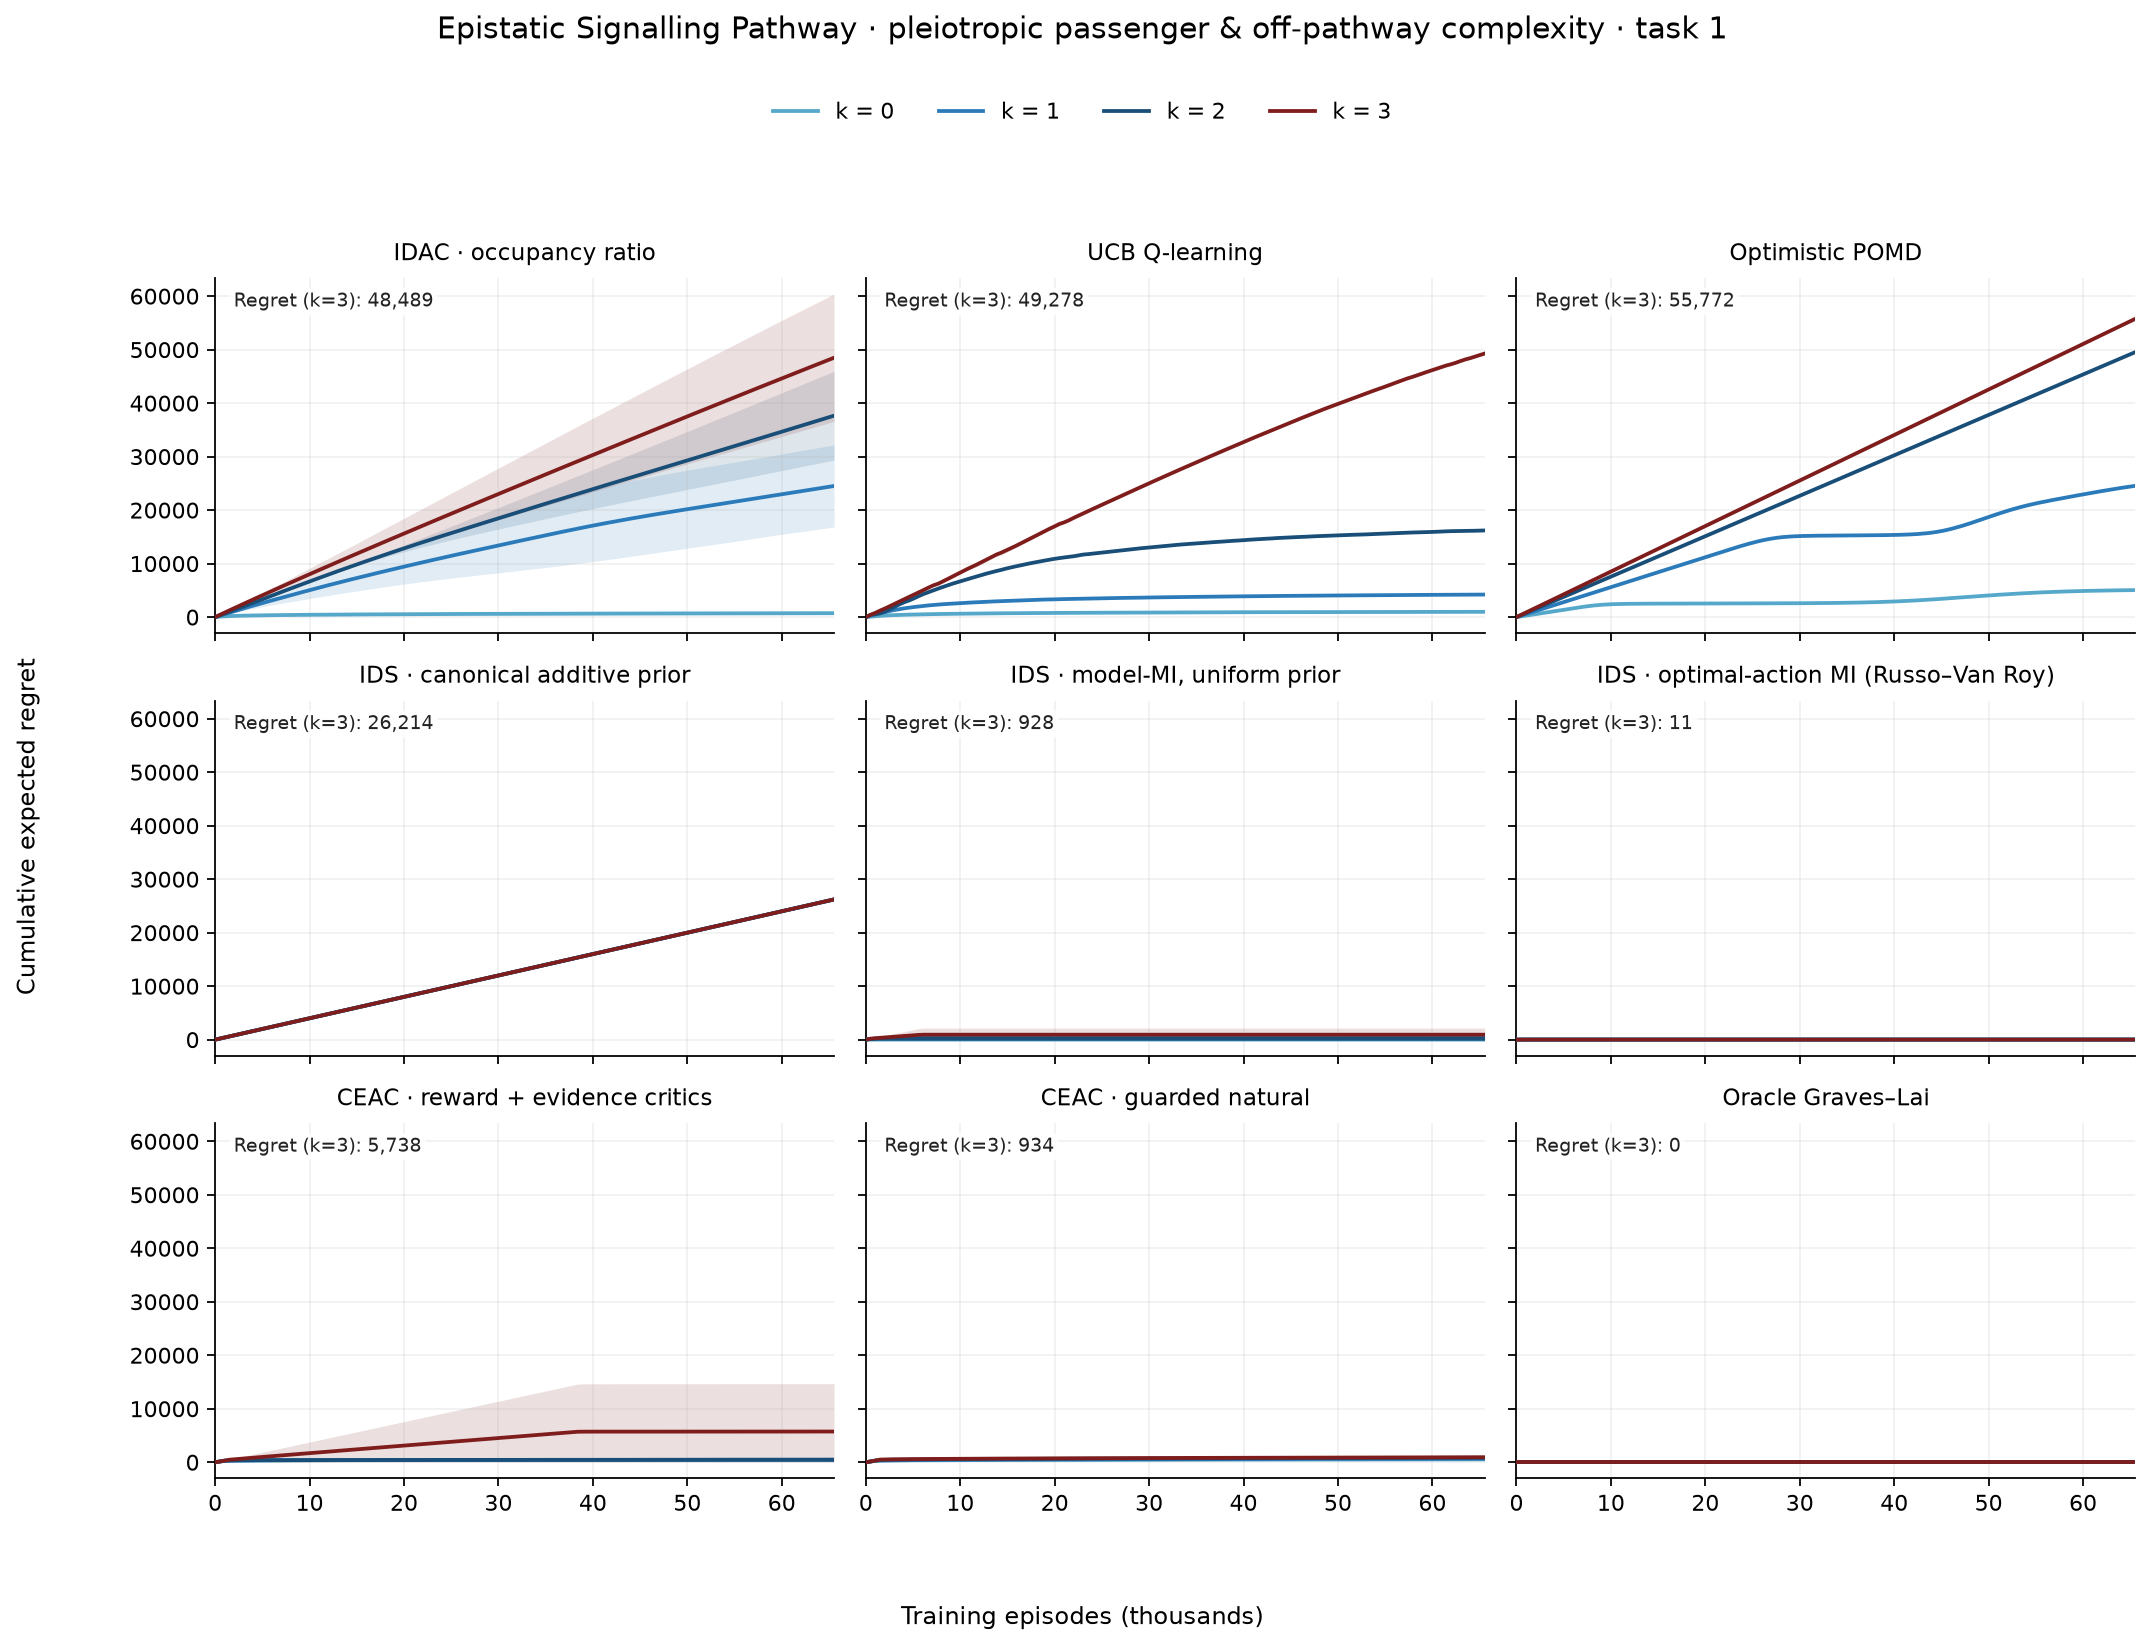

In [10]:
for metric in ("window_gap", "cumulative_regret"):
    fig = draw_learning(epistasis, "epistatic_signalling", task=1, metric=metric)
    plt.show()


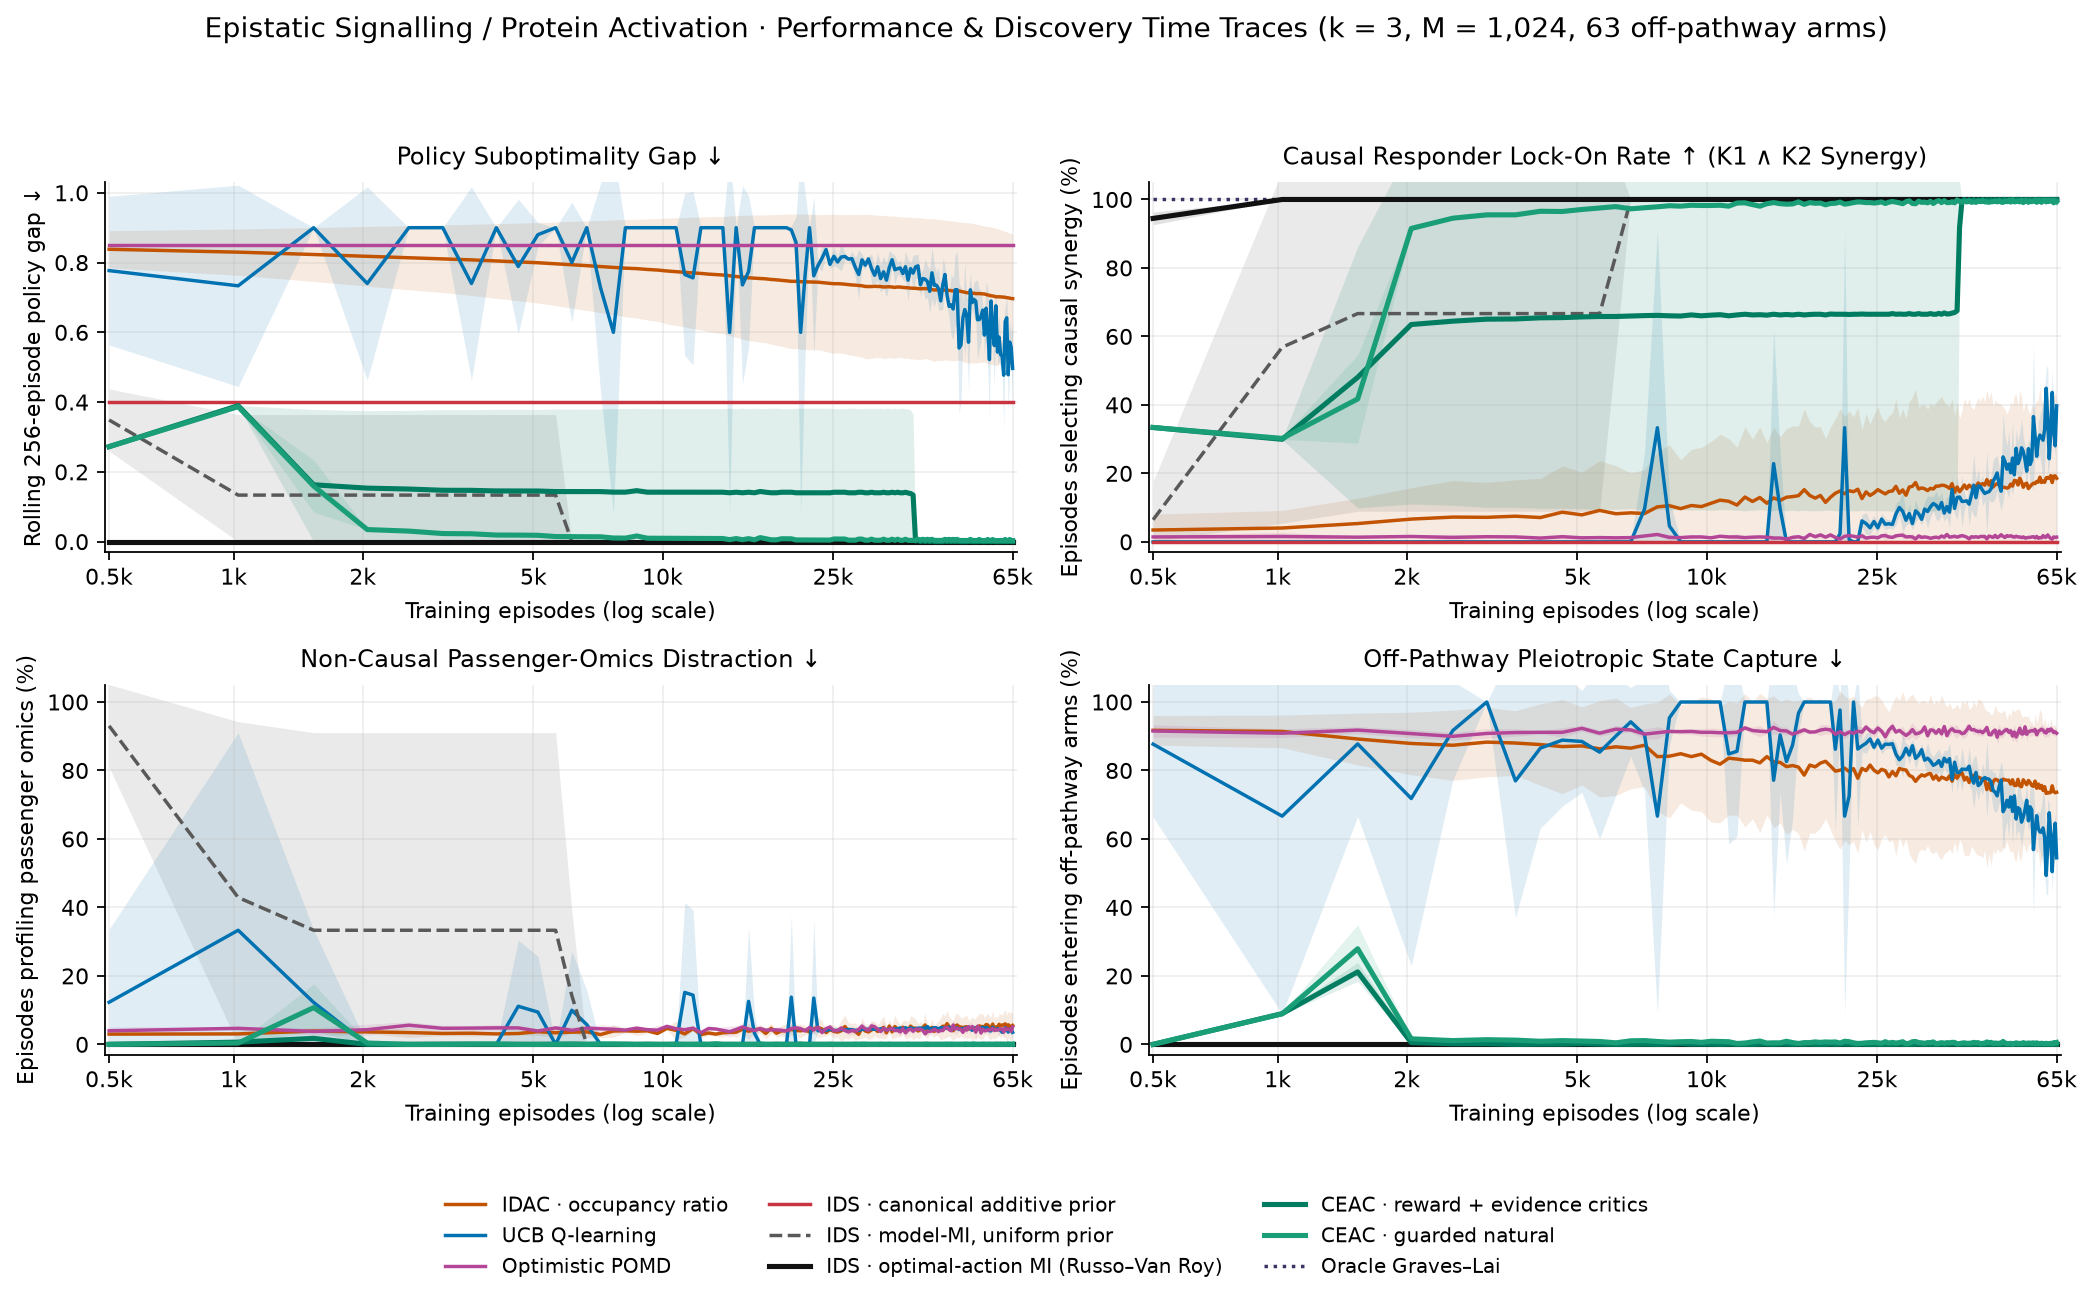

In [11]:
fig = draw_epistasis_discovery_traces(epistasis, dose=3, task=1)
plt.show()


In [12]:
epi_rows = { (r["method"], r["dose"]): r for r in endpoints(epistasis) if r["task"] == 1 }
print(f"{'Algorithm':38s} | {'k=0 Regret':>10s} | {'k=3 Regret':>10s} | {'k=3 Gap':>8s} | {'Omics%':>7s} | {'OffPath%':>8s}")
print("-" * 96)
for m in ("idac", "pomd", "ucb_q", "ids_canonical", "ids_product", "ids_action", "ceac", "ceac_natural", "oracle"):
    r0, r3 = epi_rows[(m, 0)], epi_rows[(m, 3)]
    print(
        f"{LABELS[m]:38s} | {r0['regret_mean']:10,.1f} | {r3['regret_mean']:10,.1f} | "
        f"{r3['late_gap_mean']:8.4f} | {100*r3['passenger_omics_fraction']:6.2f}% | {100*r3['pleiotropic_fraction']:7.1f}%"
    )


Algorithm                              | k=0 Regret | k=3 Regret |  k=3 Gap |  Omics% | OffPath%
------------------------------------------------------------------------------------------------
IDAC · occupancy ratio                 |      734.1 |   48,489.0 |   0.6967 |   4.39% |    79.5%
Optimistic POMD                        |    5,046.8 |   55,772.4 |   0.8510 |   4.36% |    91.4%
UCB Q-learning                         |      983.5 |   49,277.5 |   0.4967 |   4.25% |    80.3%
IDS · canonical additive prior         |   26,214.4 |   26,214.4 |   0.4000 |   0.00% |     0.0%
IDS · model-MI, uniform prior          |        7.7 |      928.2 |   0.0000 |   3.52% |     0.0%
IDS · optimal-action MI (Russo–Van Roy) |        5.0 |       11.4 |   0.0000 |   0.00% |     0.0%
CEAC · reward + evidence critics       |      438.5 |    5,738.1 |   0.0000 |   0.02% |     0.3%
CEAC · guarded natural                 |      536.1 |      934.0 |   0.0030 |   0.11% |     0.8%
Oracle Graves–Lai            

## 3. Pairwise Interaction Screen (Horlbeck 2018 K562 Matrix) & Greedy Price-Ranked CEAC (`gi_screen` + `ceac_ranked`)

Grounded in the verified Horlbeck et al. (2018, *Cell*) K562 pairwise interaction score matrix (`data/external/horlbeck2018/GI_map_treeview.zip`, SHA-256 verified offline), `select_panel(10)` selects a 10-variable panel (`45` pairs) containing one strong interaction (`FDPS–PPP2R1A`, $\text{GI} = -5.2413$) with all other 44 pairs $> -2.5$, permuted per seed to eliminate index tie-break artifacts.

### Why Greedy Disagreement + Dynamic Evidence-Price Buffer Ranking (`ceac_ranked`) Matters
1. **Eliminating uniform $\binom{G}{2}$ seed-bank floors**: Certified Section-3 `ceac` pre-registers `control` + all `45` pair arms (`46` columns $\times 513$ replay-floor episodes $\approx 23,600$ startup episodes on `gi_arrayed`). `GreedyPricedCEAC` (`ceac_ranked`) starts with `bank_size = 1` (`control`) and acquires candidate columns lazily via coordinate-free confounder-projected disagreement $\min_{j' \in C'} I^m(\pi; j')$, certifying `Task 1` with an active bank of **~2 columns** instead of `46`.
2. **Dynamic evidence-price replay ranking & KKT price attenuation**: `PriceRankedReplay` re-scores stored strata in $O(|\mathcal{B}_t|)$ whenever $\beta_t$ shifts, promoting informative strata with zero new environment steps, while attenuating effective actor exploration prices as $\rho_t = \min(1, \text{scale}(t)/(1 + t_{\text{actor}}))$ so `Task 0` (null panel) converges cleanly to `control` instead of perpetually probing low-reward pair arms.


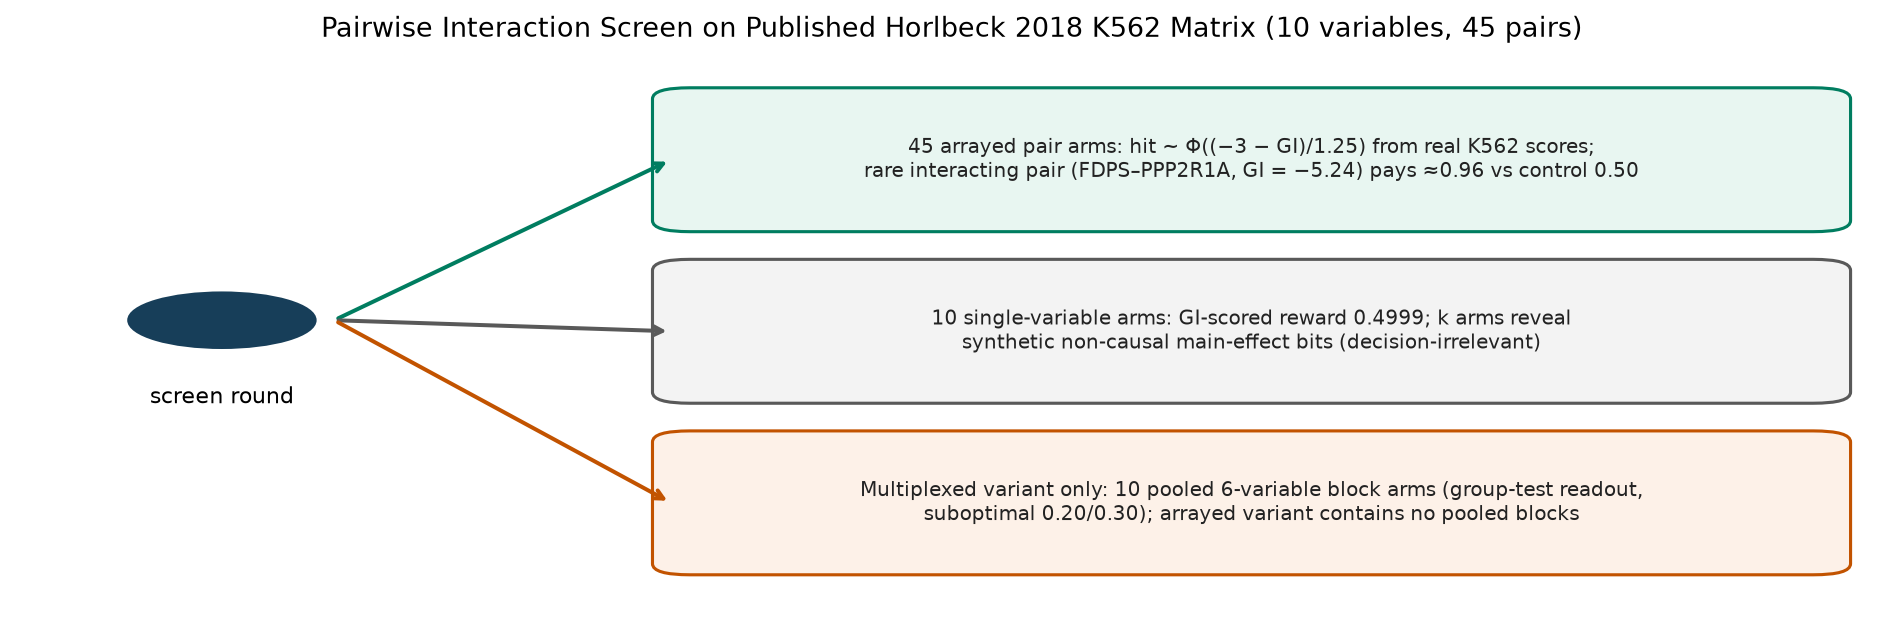

In [13]:
fig = draw_architecture("gi_screen")
plt.show()


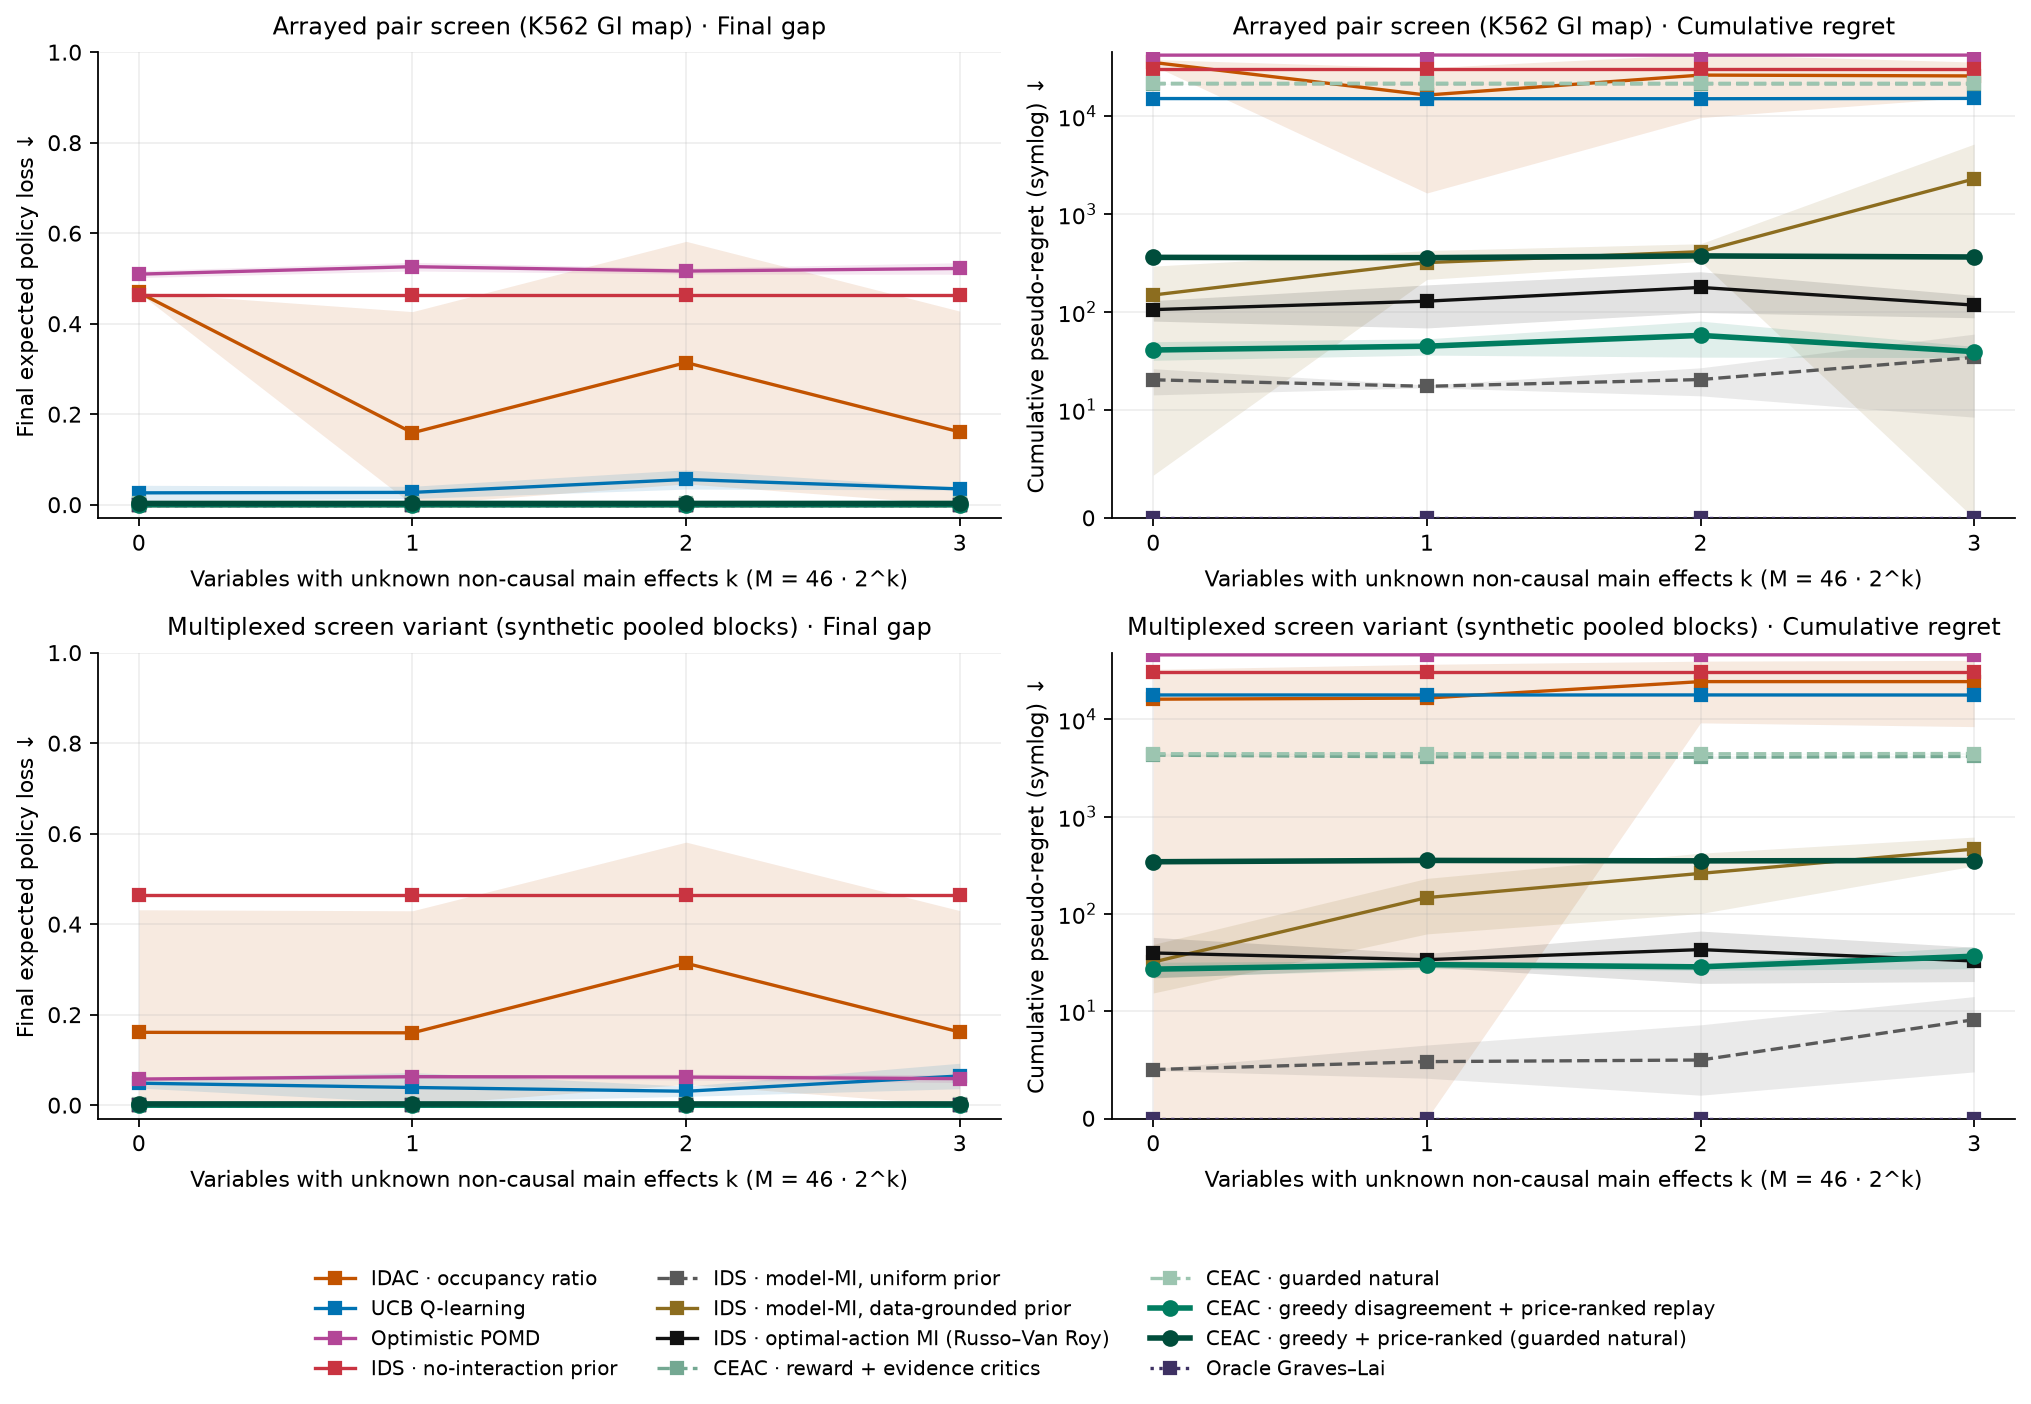

In [14]:
fig = draw_gi_ranked_response(gi_ranked["summary_rows"])
plt.show()


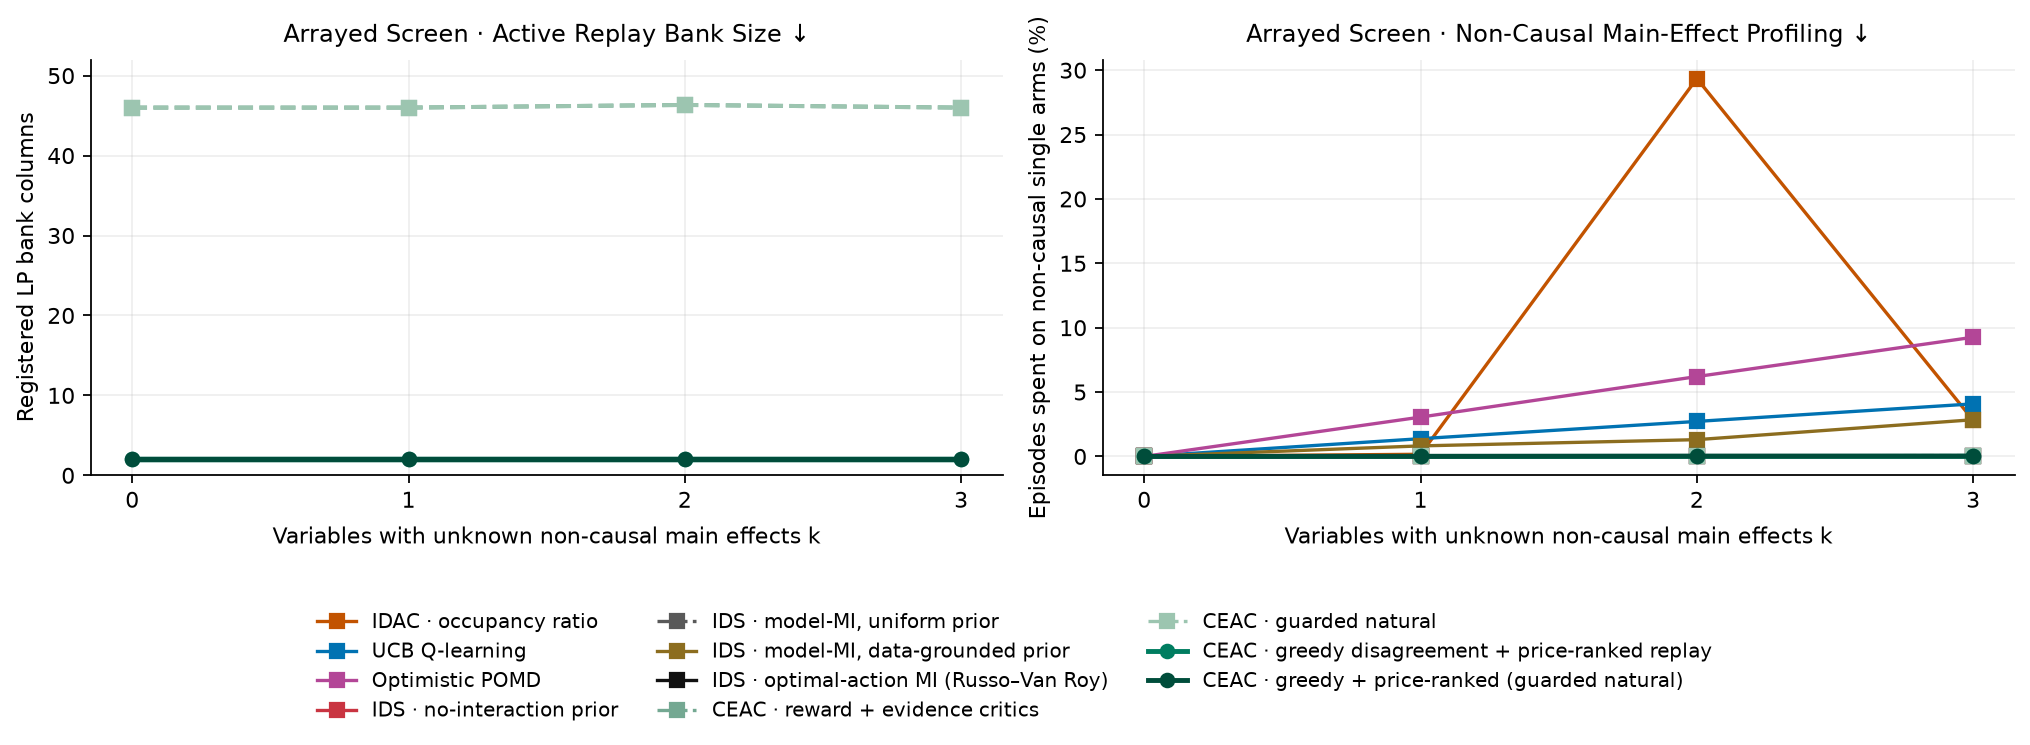

In [15]:
fig = draw_gi_ranked_mechanisms(gi_ranked["summary_rows"])
plt.show()


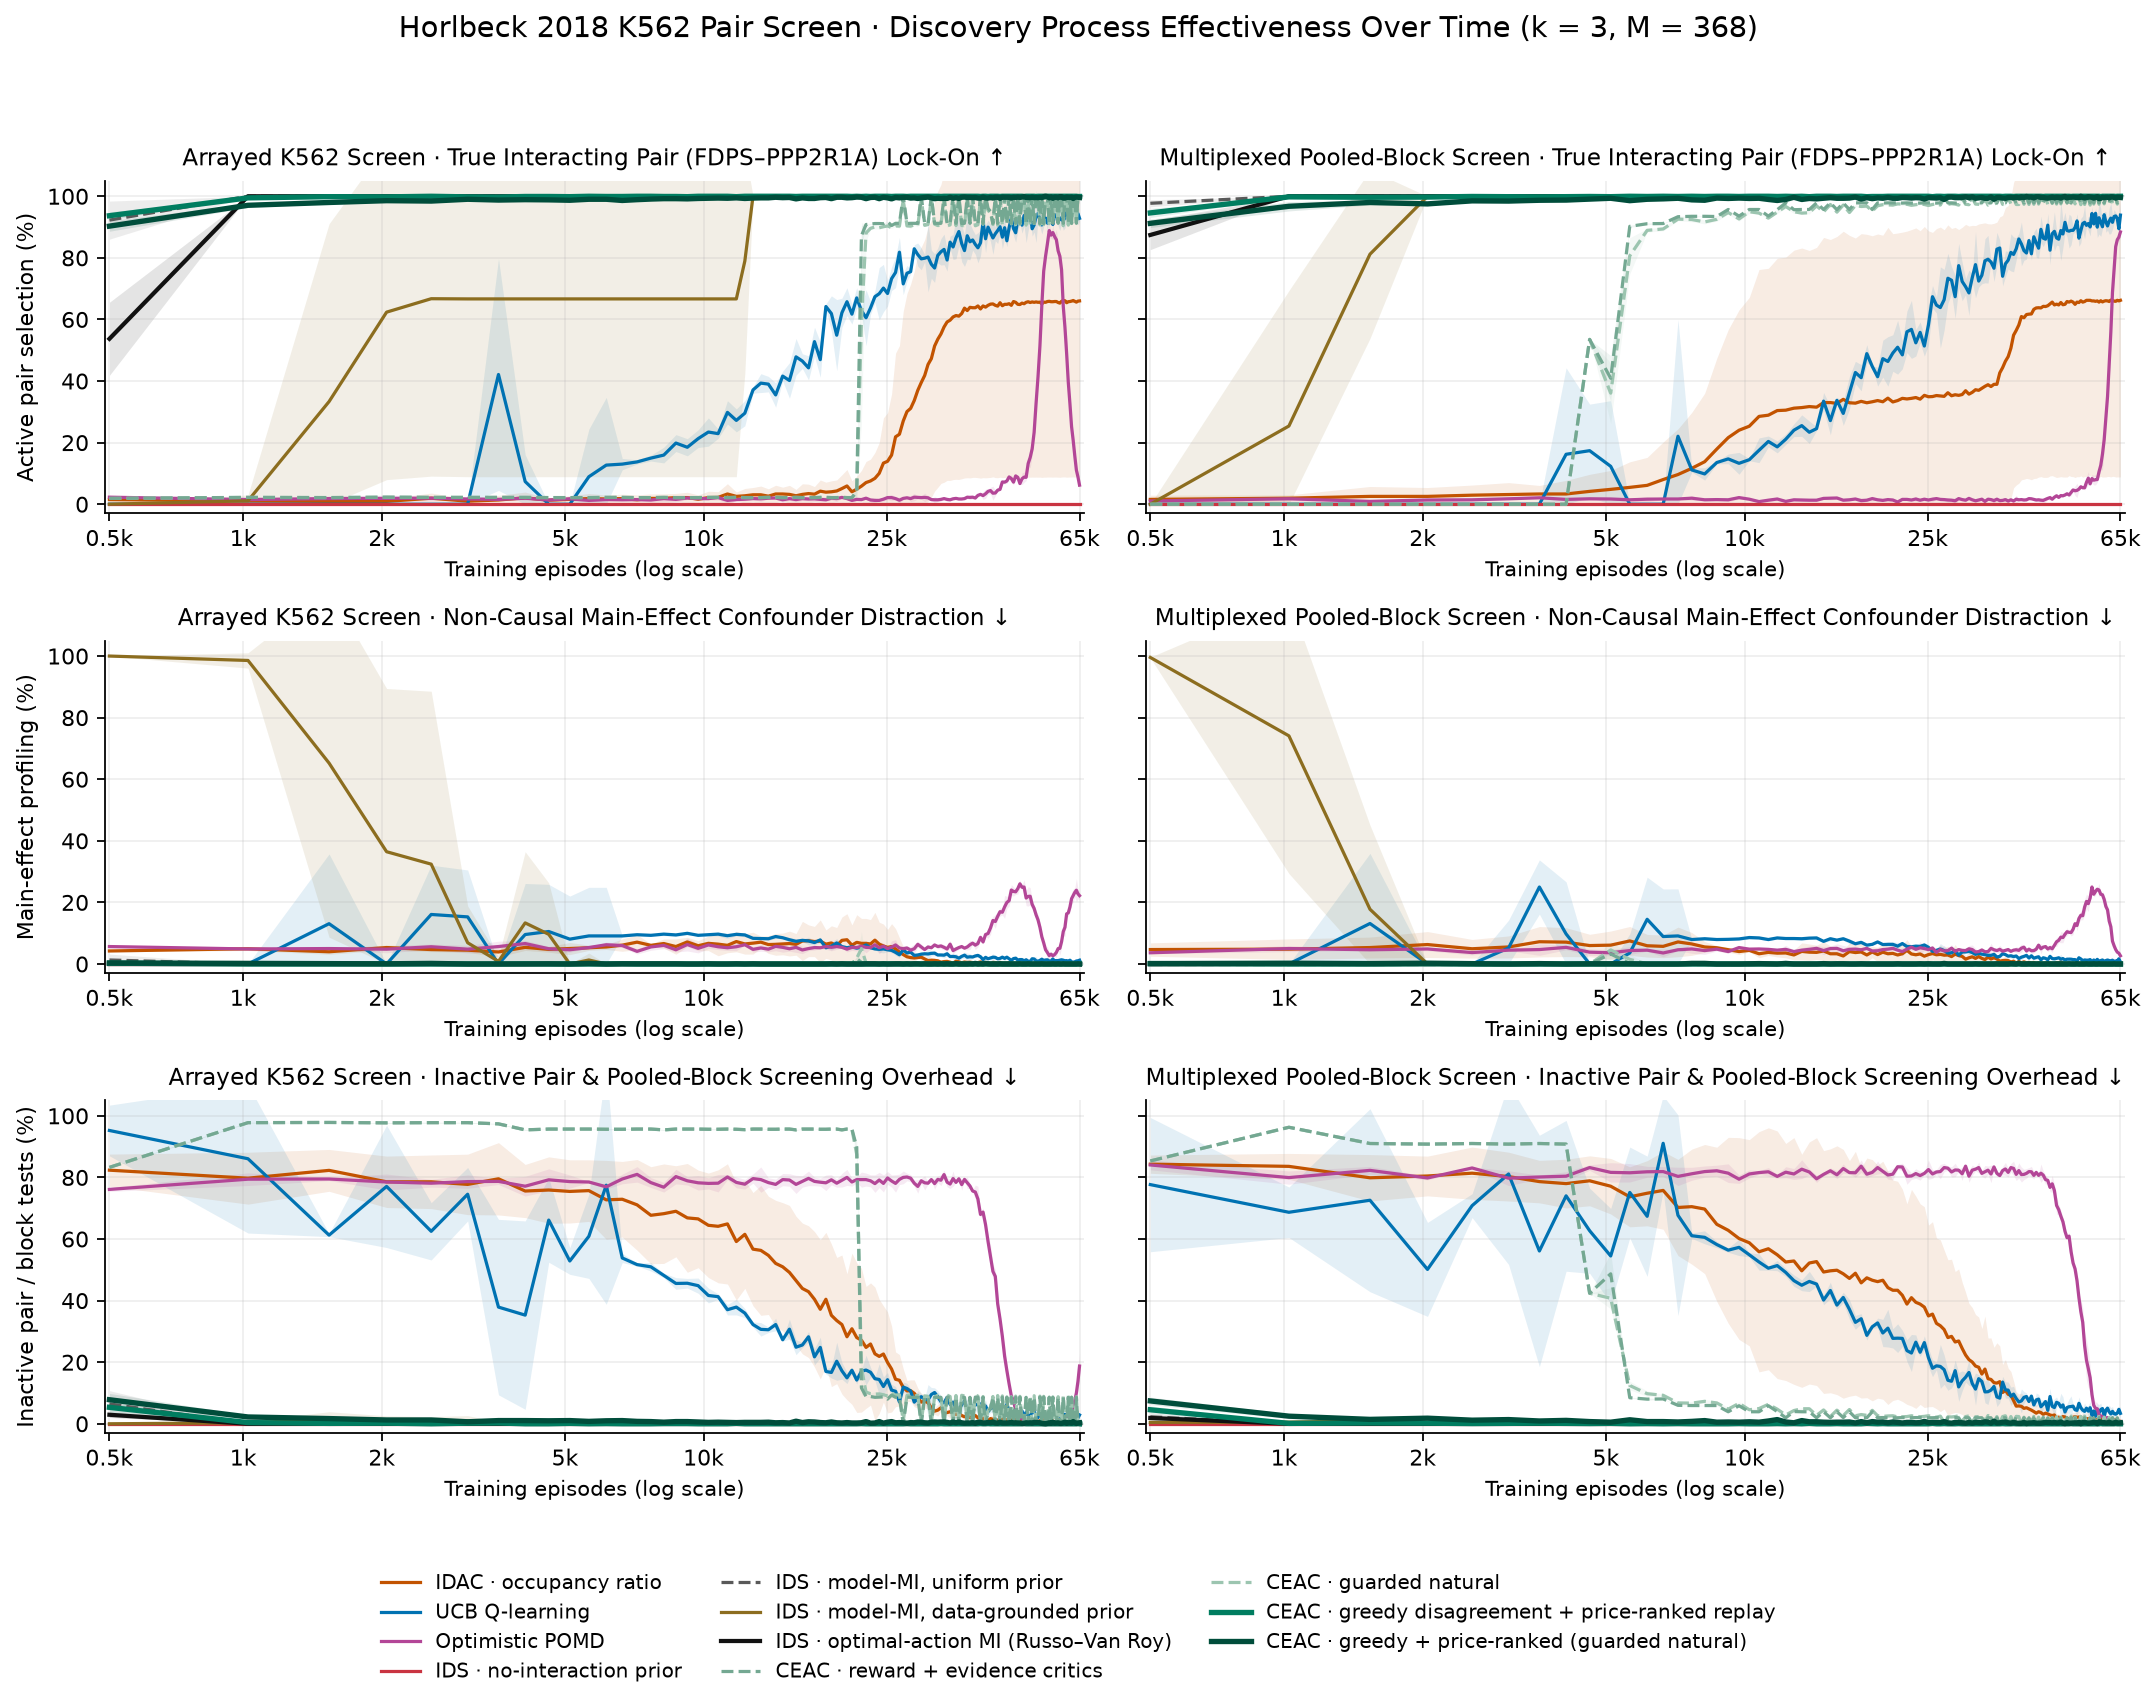

In [16]:
fig = draw_gi_discovery_traces(gi_ranked, dose=3)
plt.show()


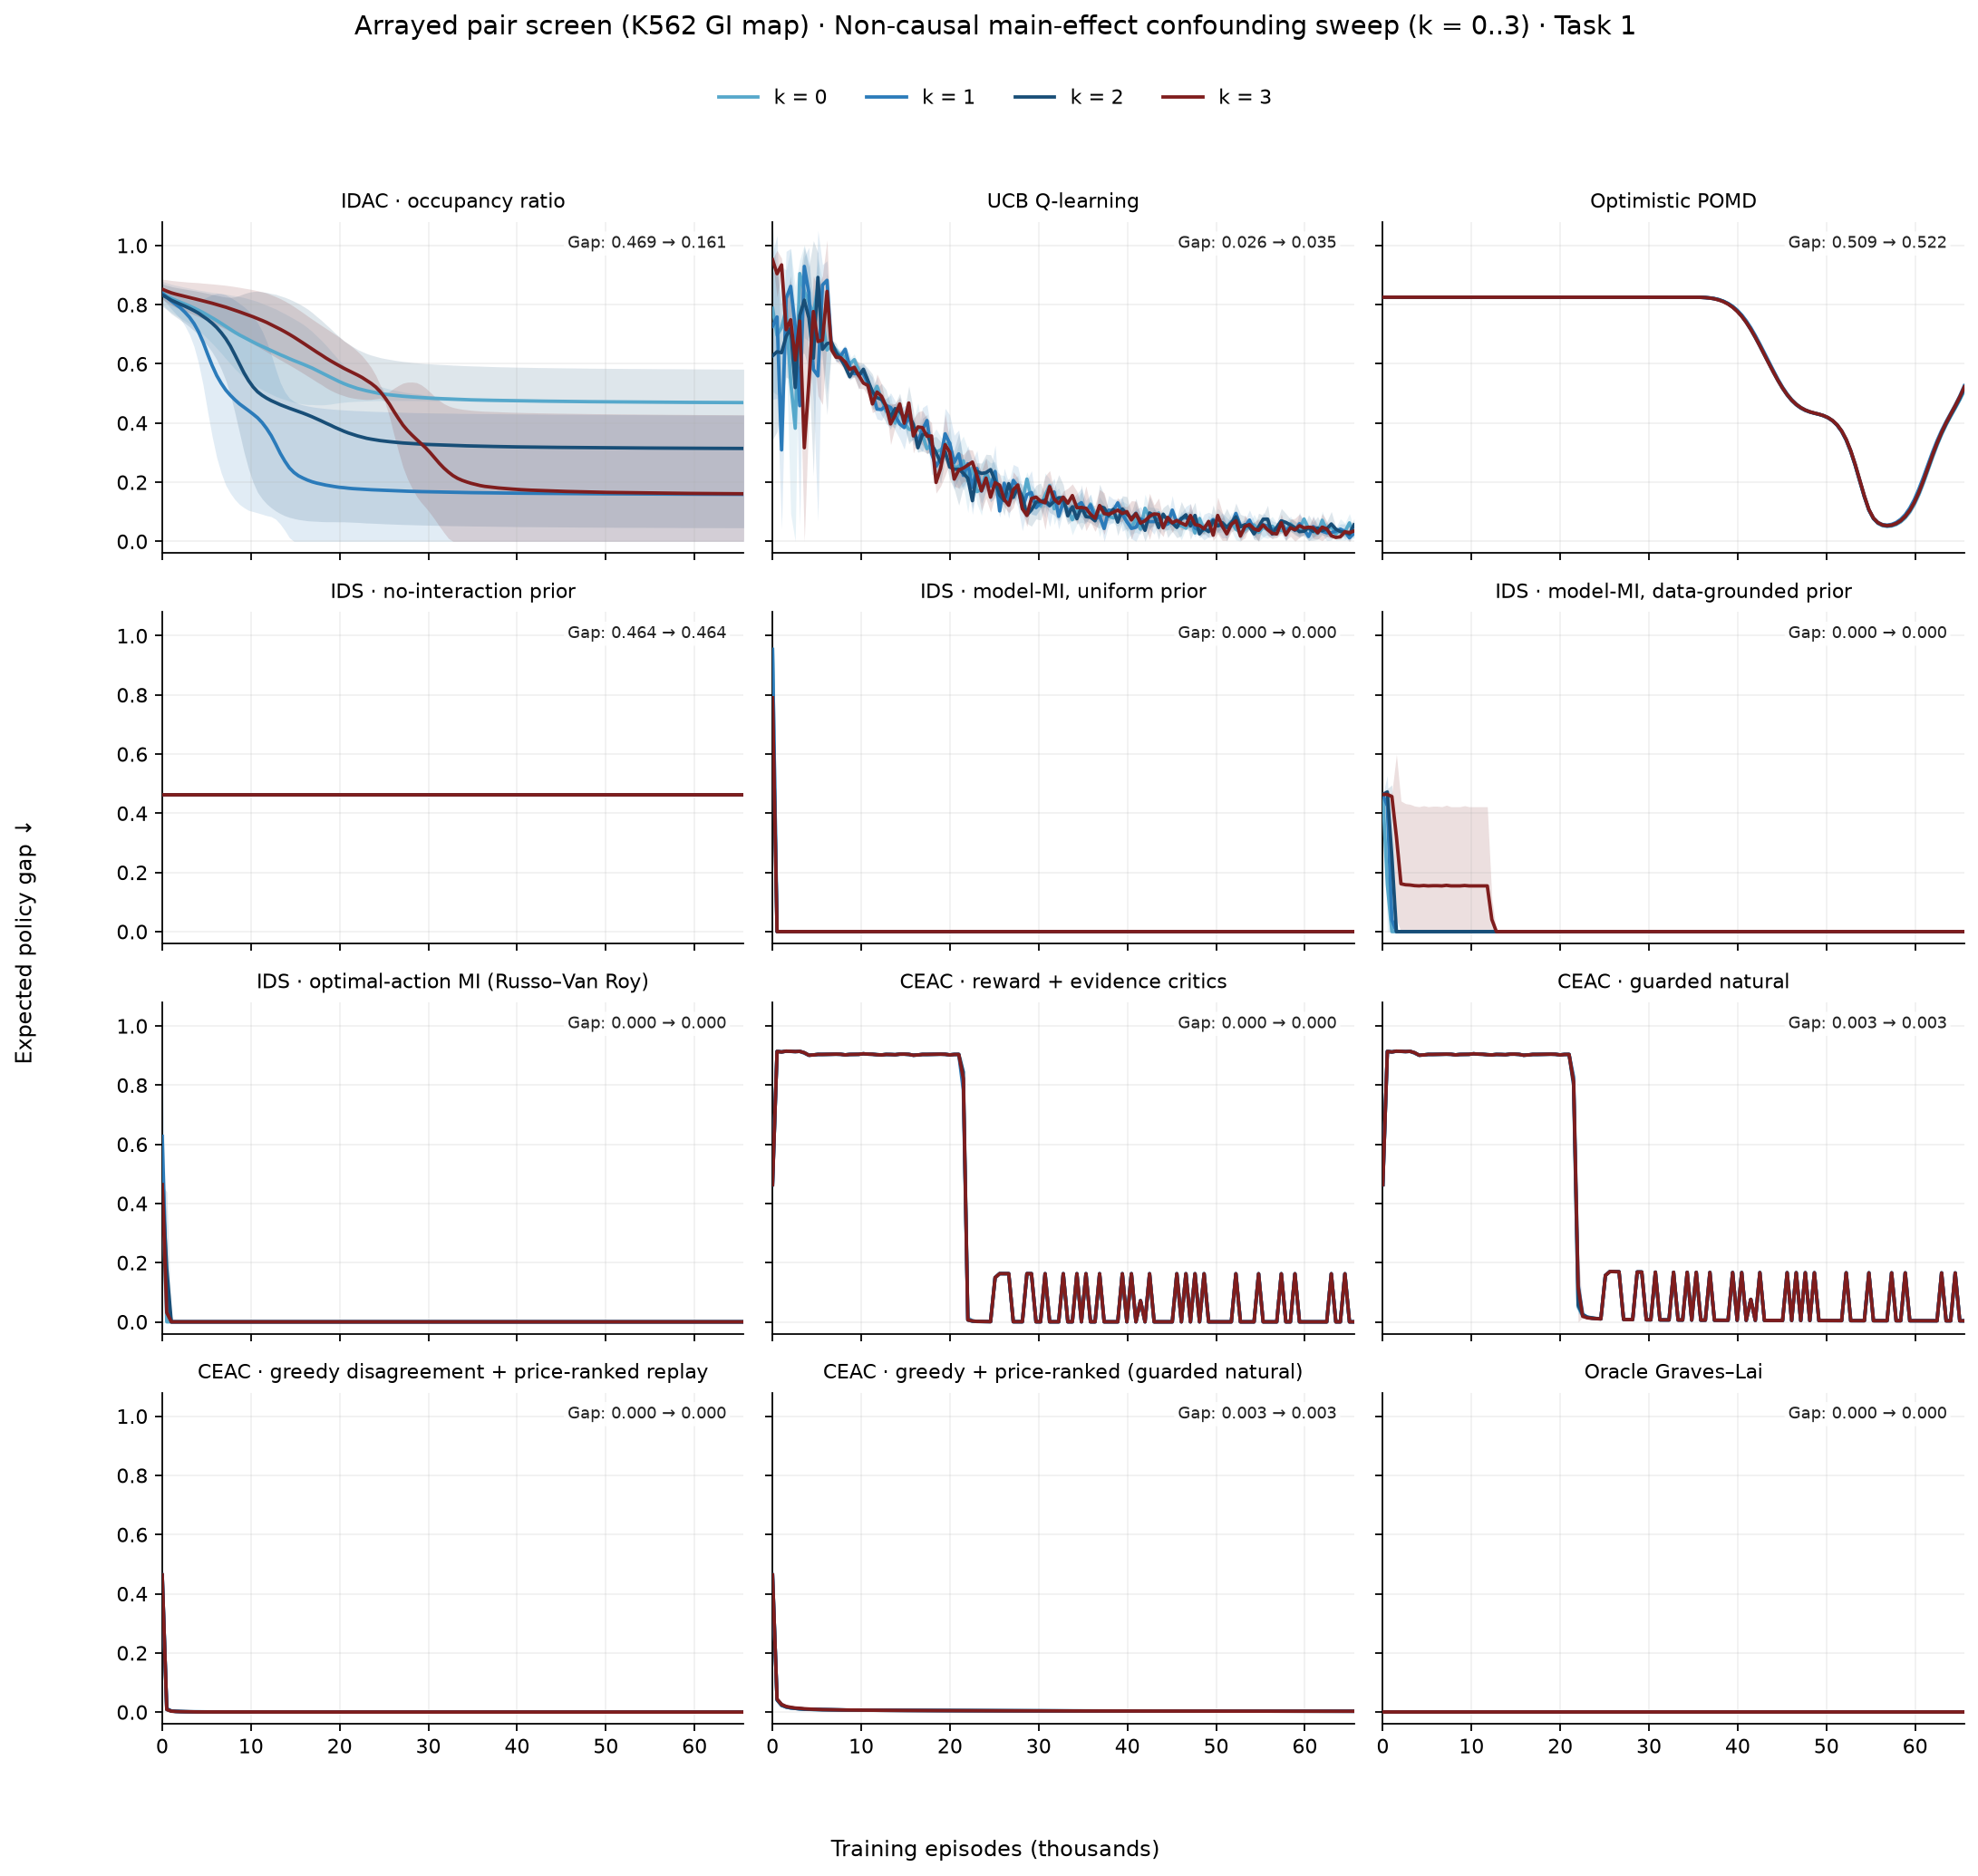

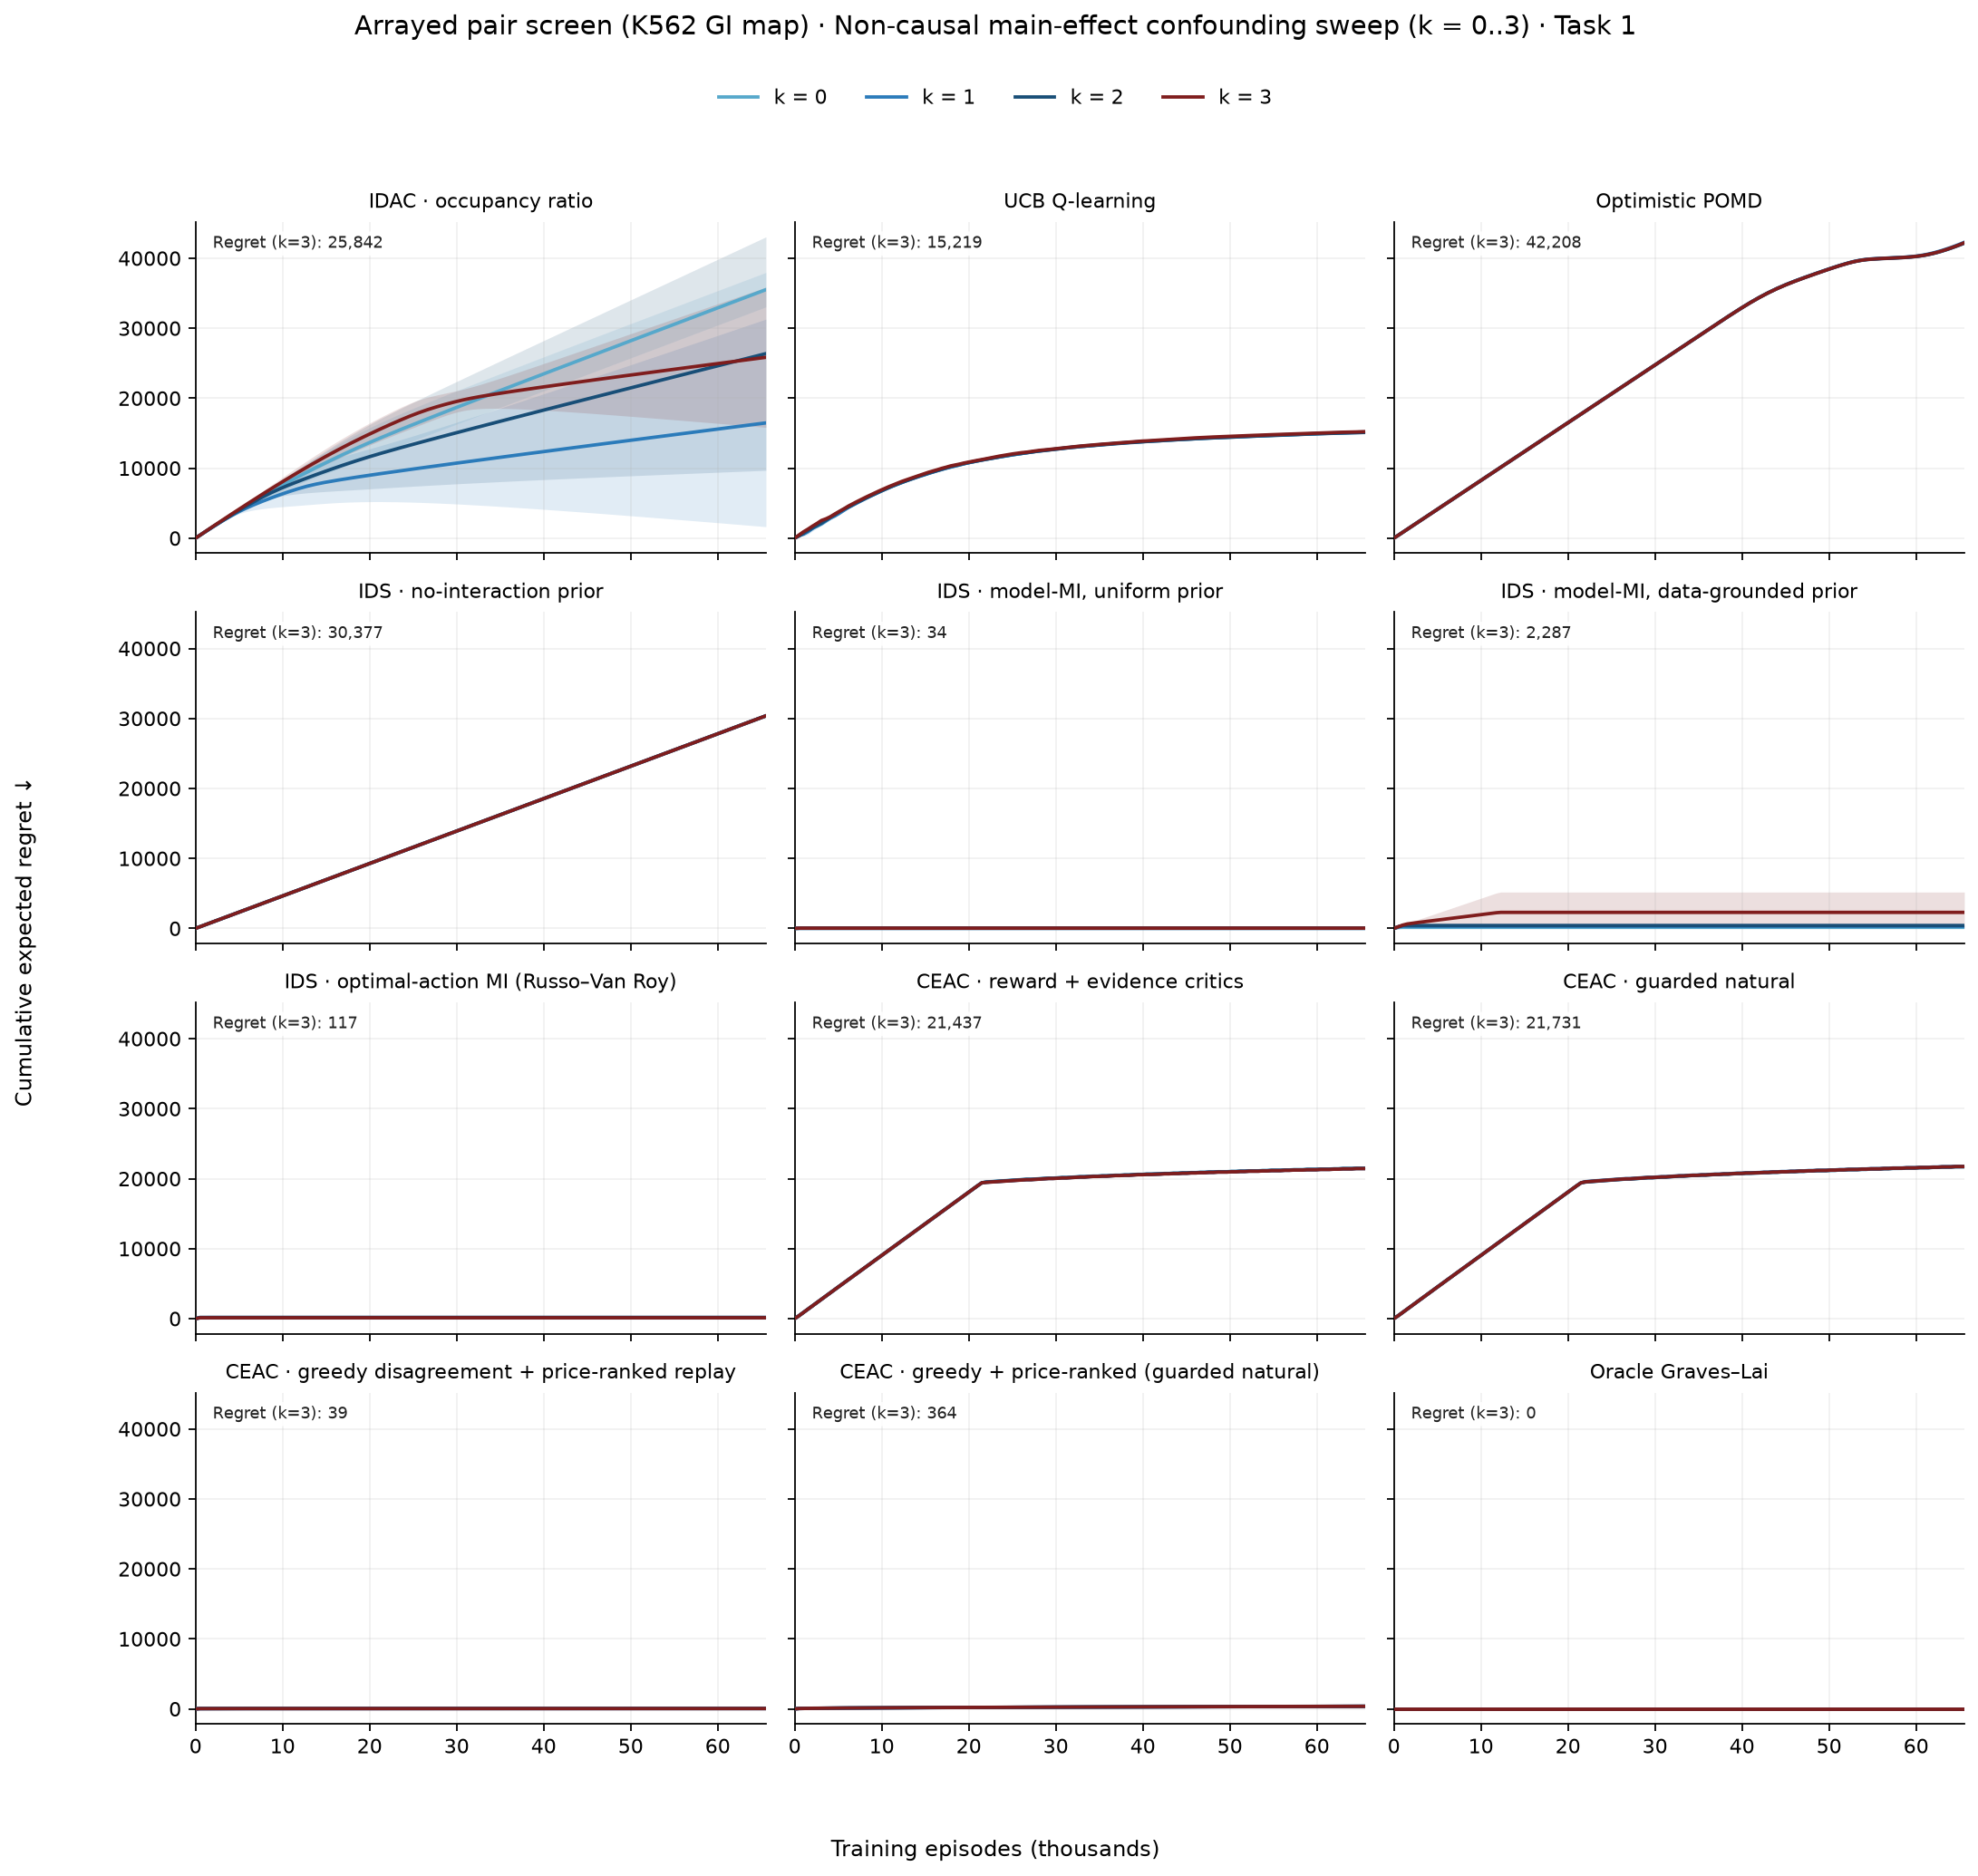

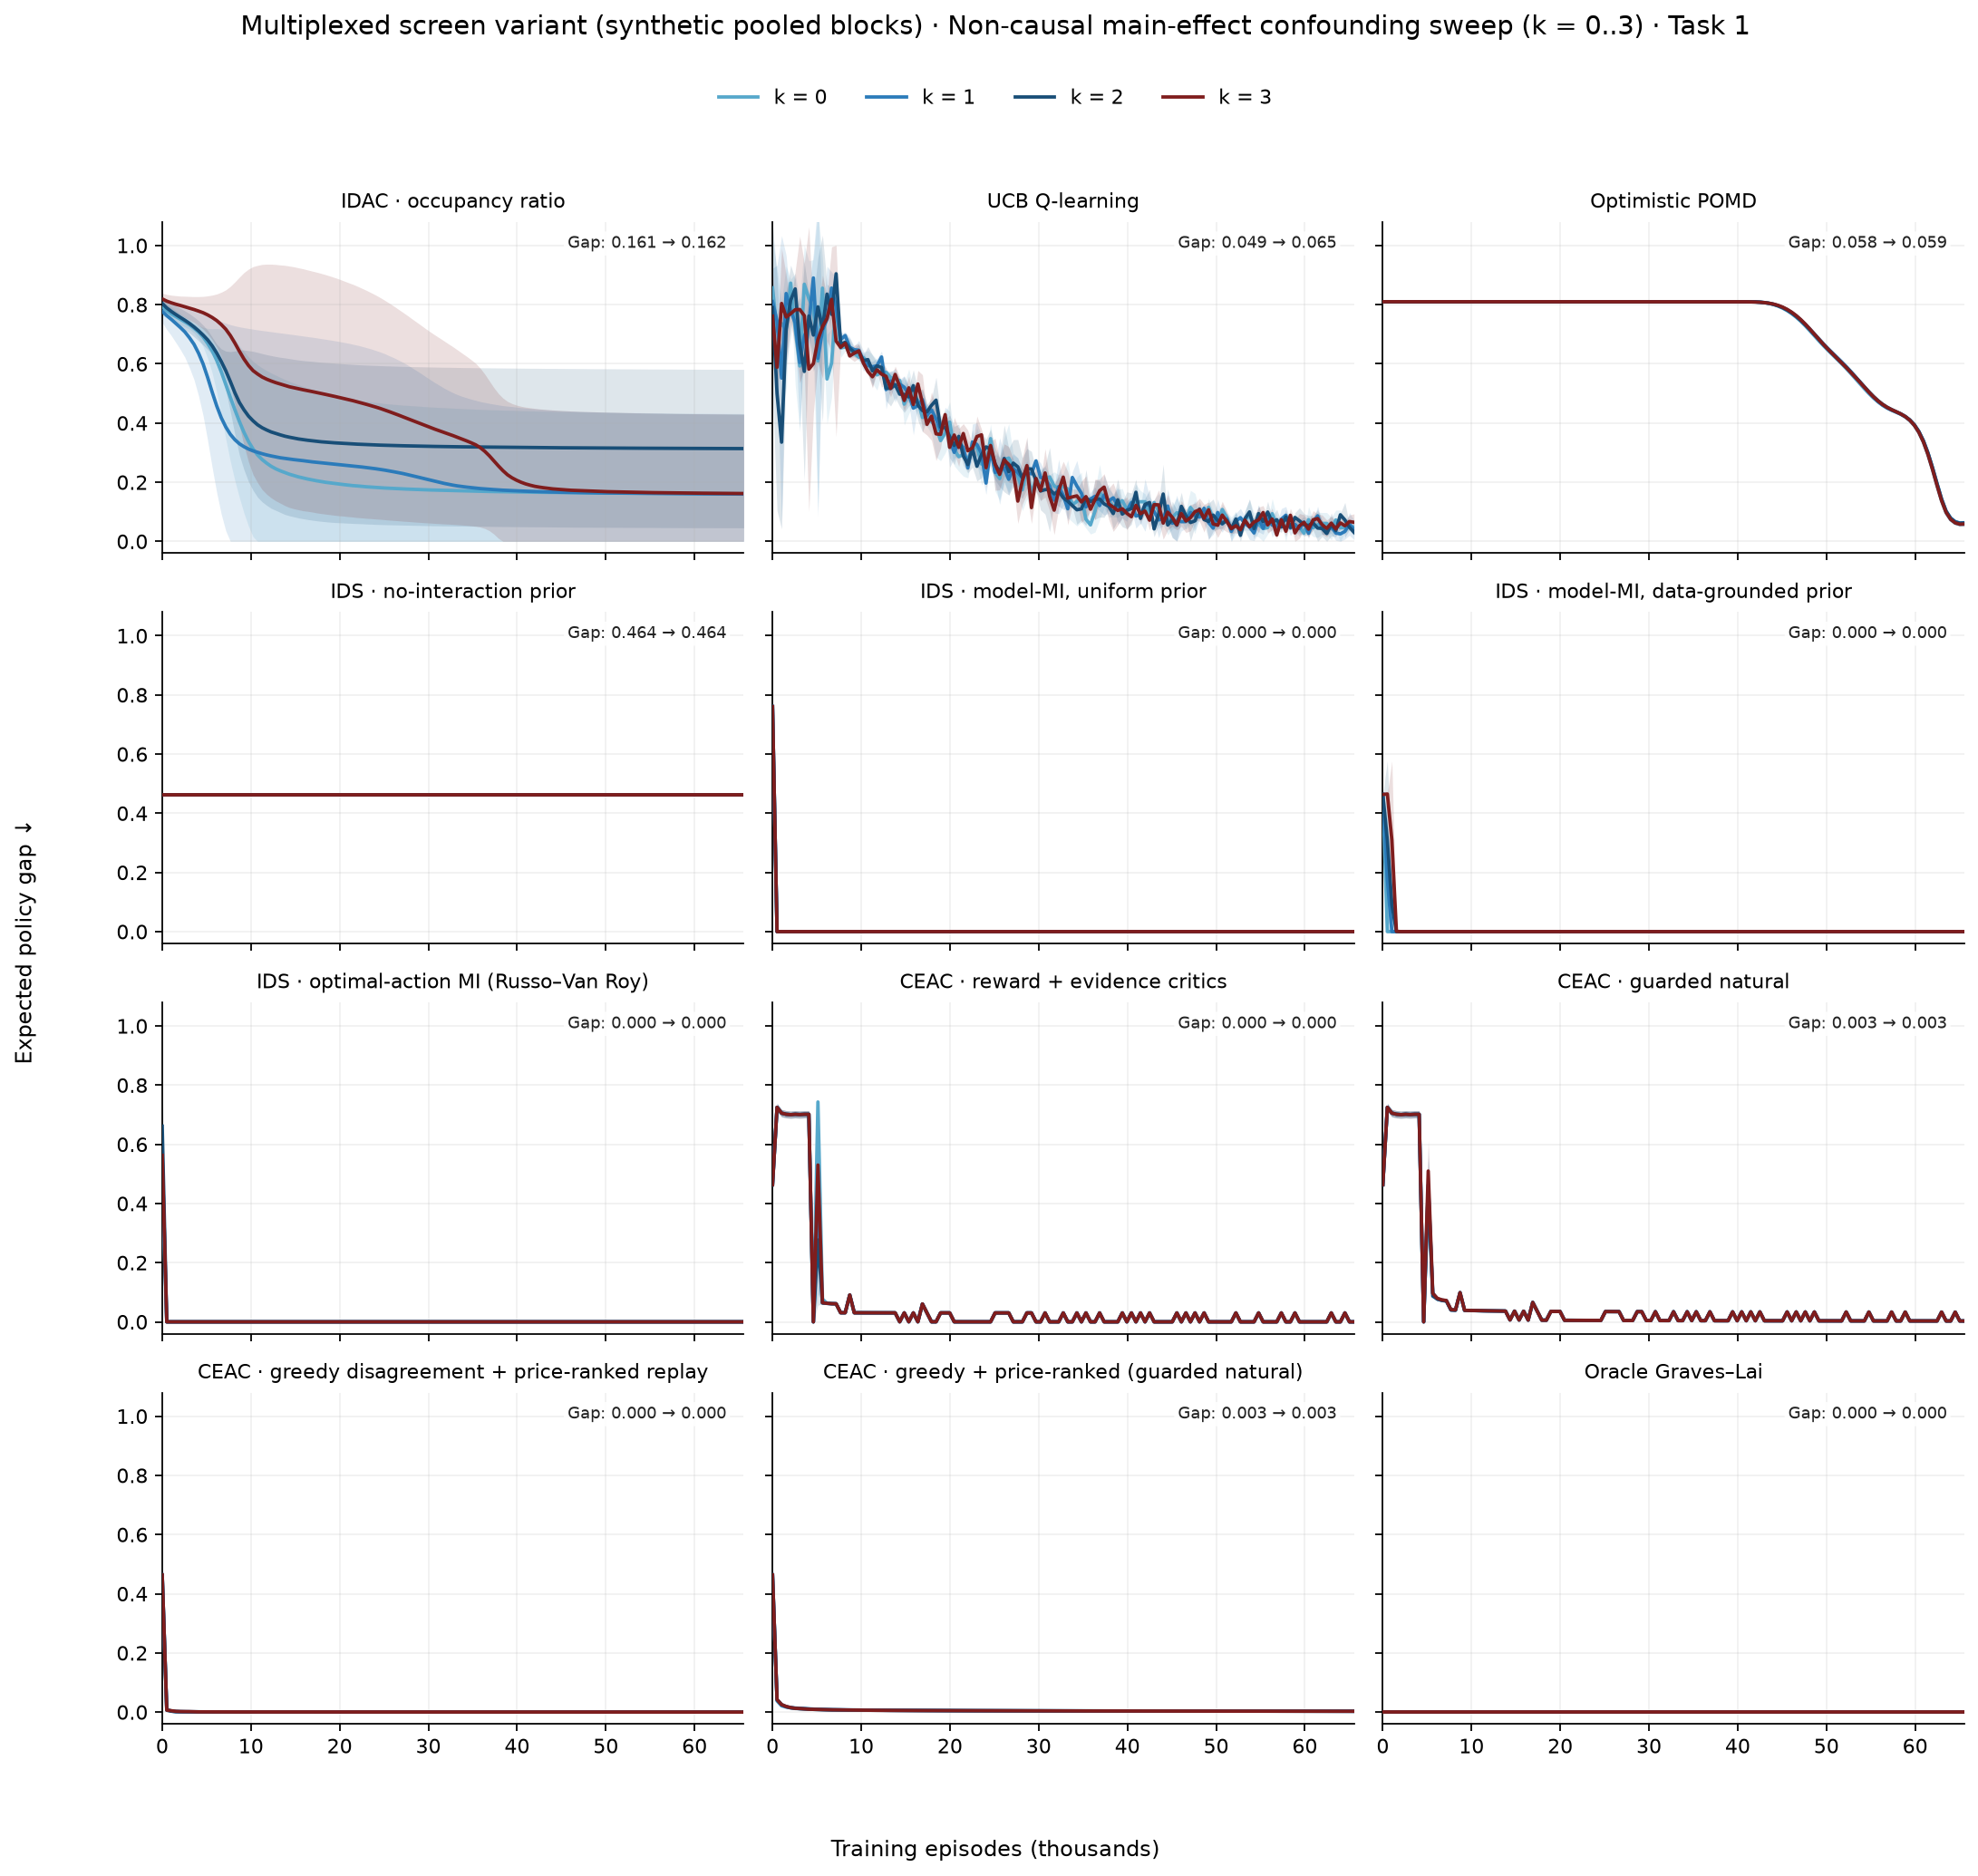

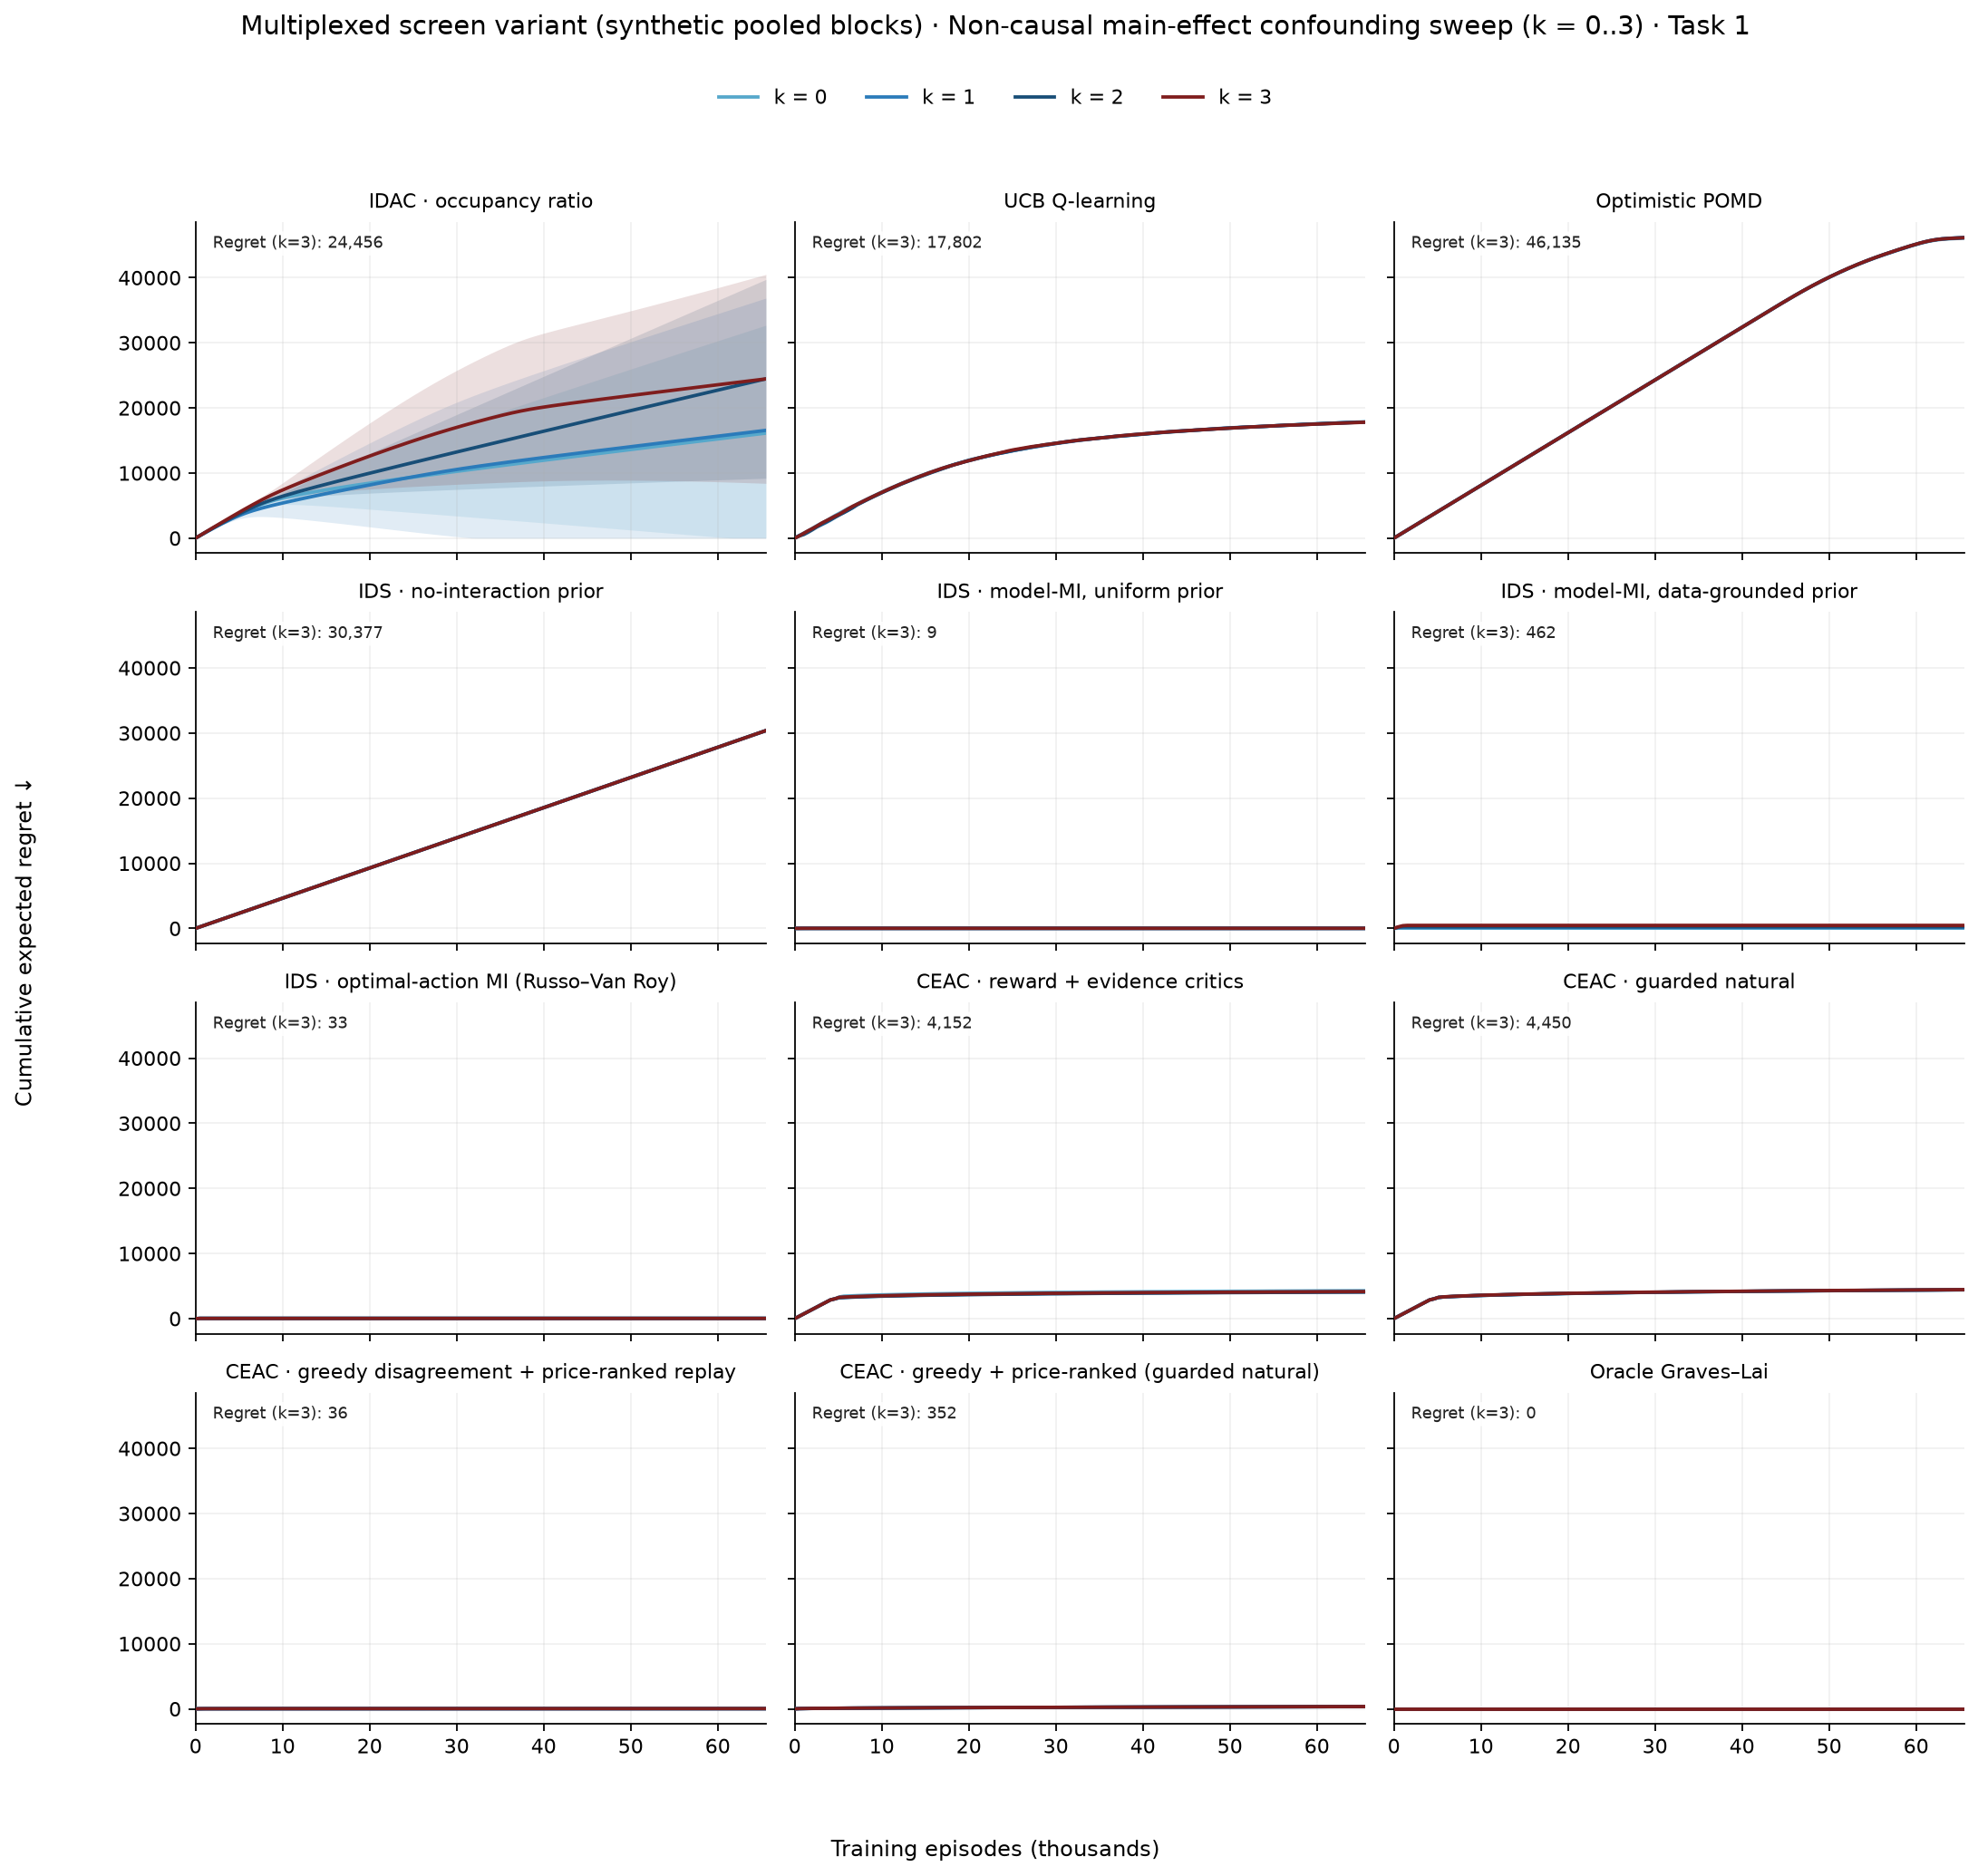

In [17]:
for kind in ("gi_arrayed", "gi_multiplexed"):
    for metric in ("window_gap", "cumulative_regret"):
        fig = draw_gi_ranked_learning(gi_ranked, kind, metric=metric)
        plt.show()


In [18]:
from collections import defaultdict

cal_by_key = defaultdict(list)
for r in gi_ranked["calibration_rows"]:
    cal_by_key[(r["kind"], r["task"], r["method"])].append(r)

print("=== Easy-Case Calibration Diagnostic (dose k=0, seeds 1001 & 1002, 65,536 episodes) ===")
print(f"{'Screen Variant':38s} | {'Task':>4s} | {'Method':46s} | {'Bank':>5s} | {'Gap':>7s} | {'Regret':>9s}")
print("-" * 122)
for (kind, task, m), grp in sorted(cal_by_key.items()):
    bank_s = f"{np.mean([x['bank_policies'] for x in grp]):5.1f}" if grp[0].get("bank_policies") is not None else "   — "
    print(
        f"{KINDS[kind][:38]:38s} | {task:4d} | {RANKED_LABELS[m][:46]:46s} | {bank_s} | "
        f"{np.mean([x['late_gap'] for x in grp]):7.4f} | {np.mean([x['cumulative_regret'] for x in grp]):9,.1f}"
    )

print("\n=== Held-Out Sweep Summary (Task 1, k=0 -> k=3, seeds 0, 1, 2) ===")
gi_map = { (r["kind"], r["method"], r["dose"]): r for r in gi_ranked["summary_rows"] if r["task"] == 1 }
print(f"{'Screen Variant':38s} | {'Method':46s} | {'k=0 Reg':>9s} | {'k=3 Reg':>9s} | {'k=3 Gap':>7s} | {'Omics%':>6s}")
print("-" * 128)
for kind in ("gi_arrayed", "gi_multiplexed"):
    for m in ("idac", "pomd", "ucb_q", "ids_additive", "ids_product", "ids_empirical", "ids_action", "ceac", "ceac_natural", "ceac_ranked", "ceac_ranked_natural", "oracle"):
        r0, r3 = gi_map[(kind, m, 0)], gi_map[(kind, m, 3)]
        print(
            f"{KINDS[kind][:38]:38s} | {RANKED_LABELS[m][:46]:46s} | {r0['regret_mean']:9,.1f} | "
            f"{r3['regret_mean']:9,.1f} | {r3['late_gap_mean']:7.4f} | {r3['profiling_pct']:5.2f}%"
        )


=== Easy-Case Calibration Diagnostic (dose k=0, seeds 1001 & 1002, 65,536 episodes) ===
Screen Variant                         | Task | Method                                         |  Bank |     Gap |    Regret
--------------------------------------------------------------------------------------------------------------------------
Arrayed pair screen (K562 GI map)      |    0 | CEAC · reward + evidence critics               |  46.0 |  0.3947 |  27,465.9
Arrayed pair screen (K562 GI map)      |    0 | CEAC · guarded natural                         |  46.0 |  0.3158 |  24,645.3
Arrayed pair screen (K562 GI map)      |    0 | CEAC · greedy disagreement + price-ranked repl |  46.0 |  0.0000 |     228.7
Arrayed pair screen (K562 GI map)      |    0 | CEAC · greedy + price-ranked (guarded natural) |  46.0 |  0.0013 |     380.0
Arrayed pair screen (K562 GI map)      |    0 | IDS · optimal-action MI (Russo–Van Roy)        |    —  |  0.0000 |      45.3
Arrayed pair screen (K562 GI map)      

## 4. Experimental Runners & Reproducible CLI Entrypoints

All studies and portable evidence bundles can be reproduced from the repository root or invoked programmatically via the entrypoints below (disabled by default during notebook verification so rendering remains instantaneous and deterministic):


In [19]:
RUNNER_COMMANDS = {
    "unit_tests": ".venv/bin/python -m unittest discover -s tests/pathologies -v",
    "locks_and_epistasis_suite": ".venv/bin/python scripts/run_pathologies_suite.py --tag repro_v1 --workers 10 --protocols locks epistasis",
    "gi_ranked_study": ".venv/bin/python -m ceac_ranked.study --tag repro_ranked_v1 --workers 10",
    "rebuild_this_notebook": ".venv/bin/python scripts/render_pathologies_notebook.py --execute",
}
for name, cmd in RUNNER_COMMANDS.items():
    print(f"[{name}]\n  {cmd}")


[unit_tests]
  .venv/bin/python -m unittest discover -s tests/pathologies -v
[locks_and_epistasis_suite]
  .venv/bin/python scripts/run_pathologies_suite.py --tag repro_v1 --workers 10 --protocols locks epistasis
[gi_ranked_study]
  .venv/bin/python -m ceac_ranked.study --tag repro_ranked_v1 --workers 10
[rebuild_this_notebook]
  .venv/bin/python scripts/render_pathologies_notebook.py --execute
